In [1]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

def leer_evolucion(carpeta, instancia):
    """Lee resultados/<instancia>_evolucion.csv (instancia sin .txt)."""
    return pd.read_csv(os.path.join(carpeta, instancia + "_evolucion.csv"))

def graficar(instancia, carpetas, ref=None, ax=None, guardar=None):
    """Evolución del mejor objetivo de una instancia, una curva por carpeta.
    ref: valor de referencia (por ejemplo, el del anexo de Lam et al.)."""
    if isinstance(carpetas, str):
        carpetas = [carpetas]
    nuevo = ax is None
    if nuevo:
        fig, ax = plt.subplots(figsize=(8, 4.5))
    for carpeta in carpetas:
        df = leer_evolucion(carpeta, instancia)
        ax.step(df["tiempo_s"], df["mejor_objetivo"], where="post", linewidth=1.8,
                label=carpeta.replace("resultados_", ""))
    if ref is not None:
        ax.axhline(ref, color="gray", linestyle="--", linewidth=1.2, label="referencia: %g" % ref)
    ax.set_title(instancia)
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Mejor objetivo")
    ax.grid(True, alpha=0.3)
    ax.legend()
    if nuevo:
        plt.tight_layout()
        if guardar:
            plt.savefig(guardar, dpi=150)
        plt.show()

In [2]:
carpeta = "resultados_thompson_s0"
instancias = sorted(os.path.basename(f).replace("_evolucion.csv", "")
                    for f in glob.glob(os.path.join(carpeta, "*_evolucion.csv")))
print(len(instancias), "instancias")
instancias[:10]

180 instancias


['10_1000_1000_10_10',
 '10_1000_1000_10_20',
 '10_1000_1000_10_30',
 '10_1000_1000_10_40',
 '10_1000_1000_10_5',
 '10_1000_1000_10_50',
 '10_1000_5000_10_10',
 '10_1000_5000_10_20',
 '10_1000_5000_10_30',
 '10_1000_5000_10_40']

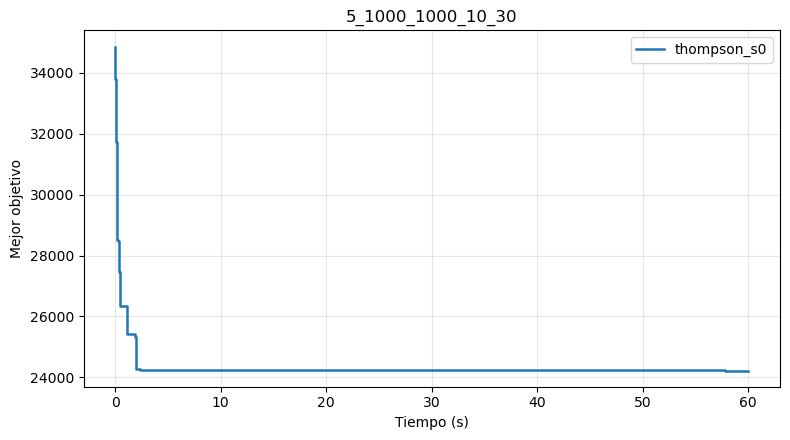

In [3]:
graficar("5_1000_1000_10_30", "resultados_thompson_s0")

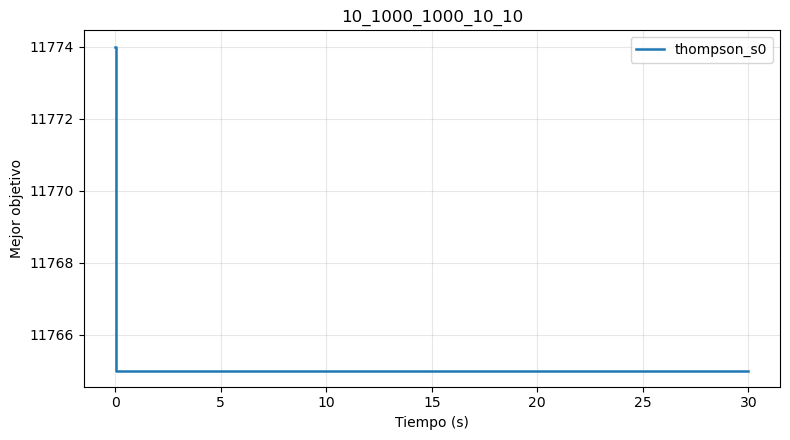

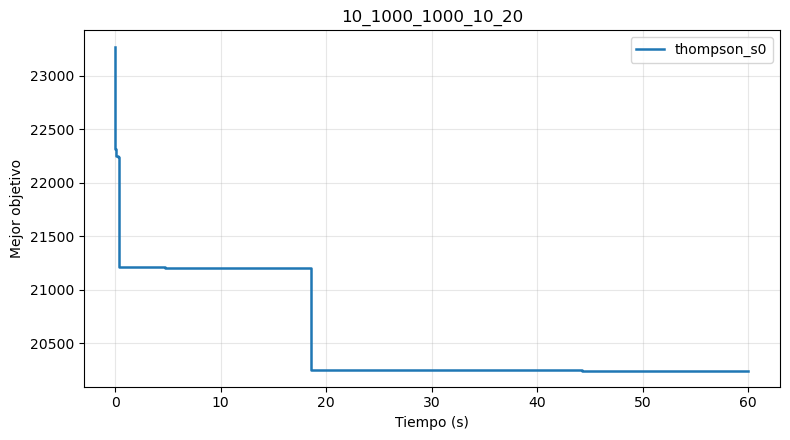

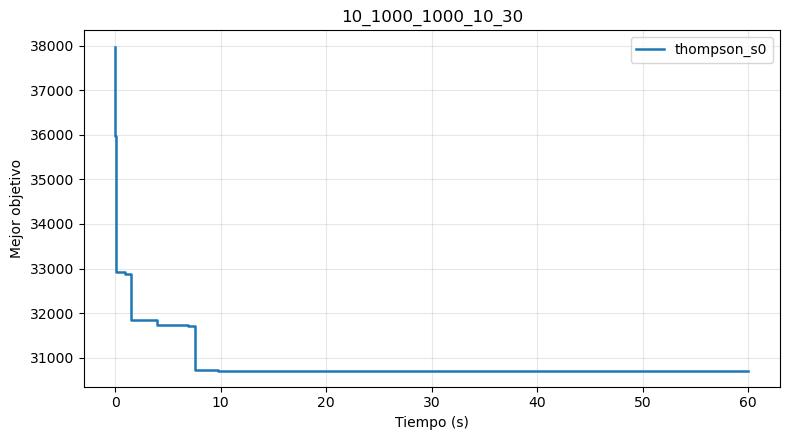

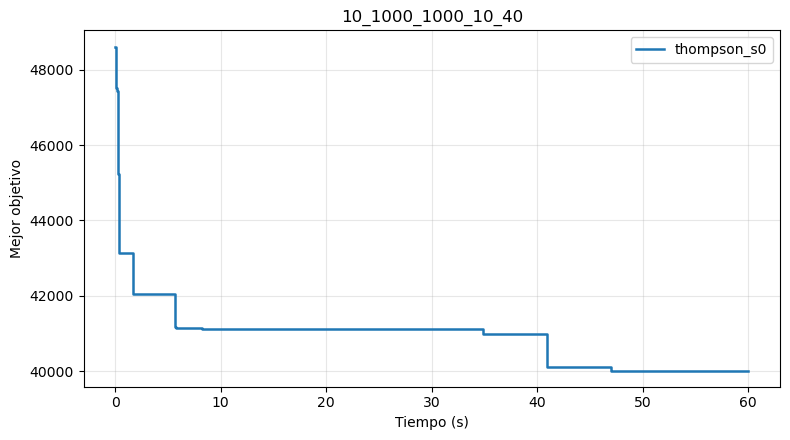

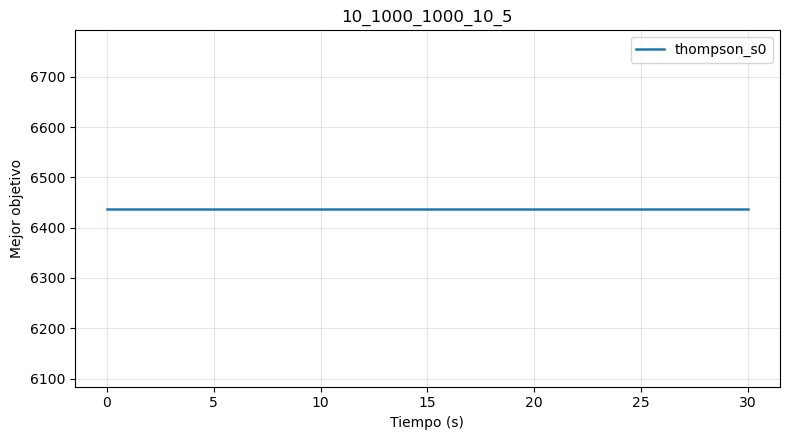

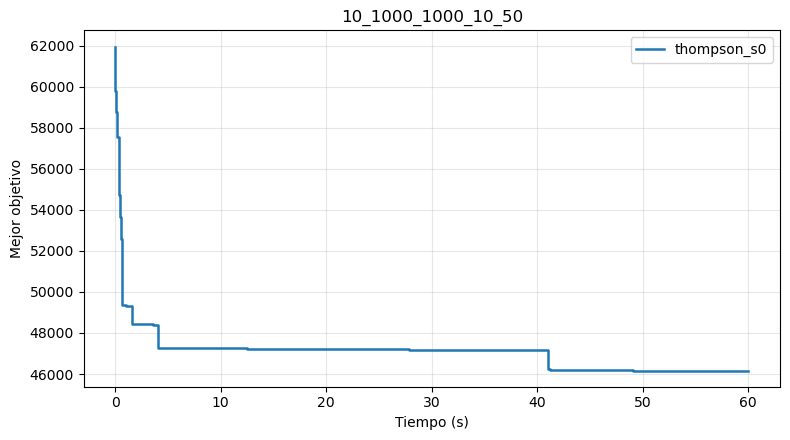

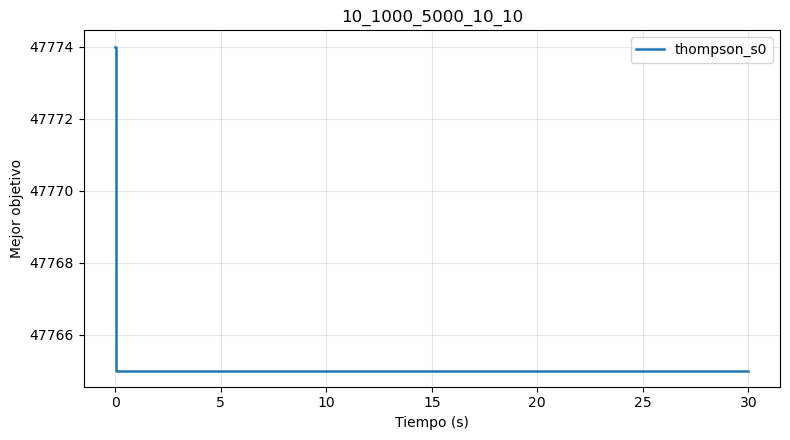

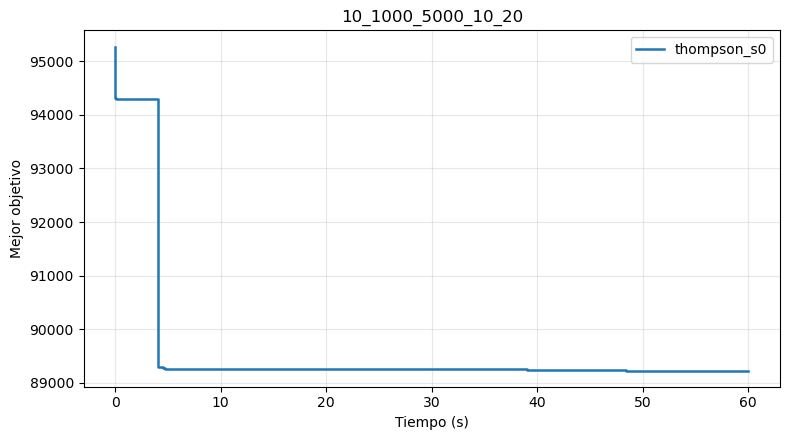

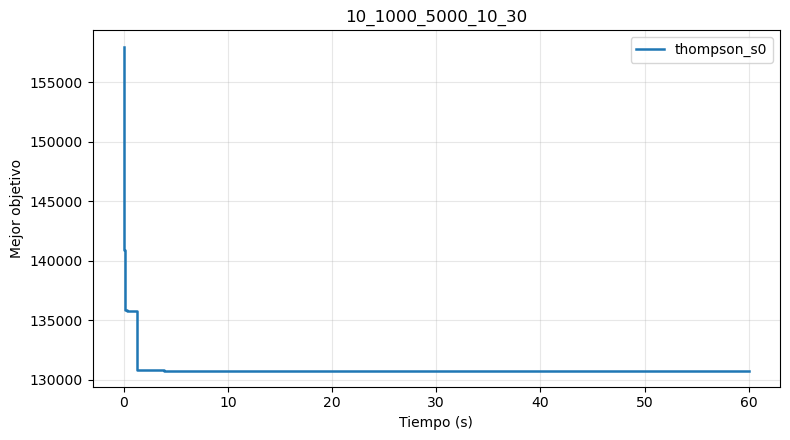

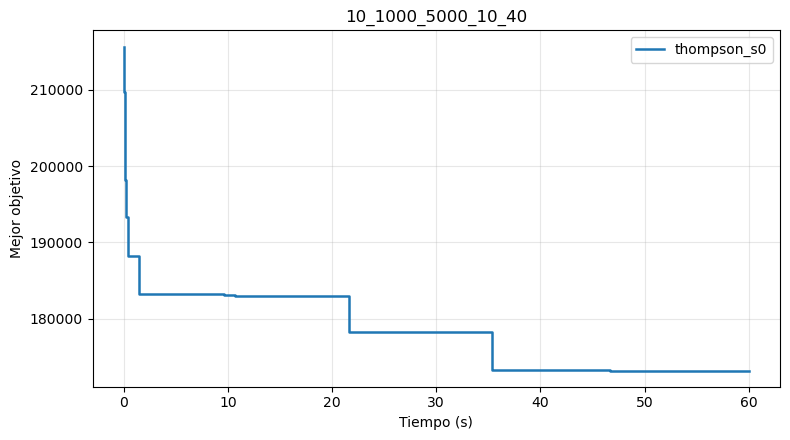

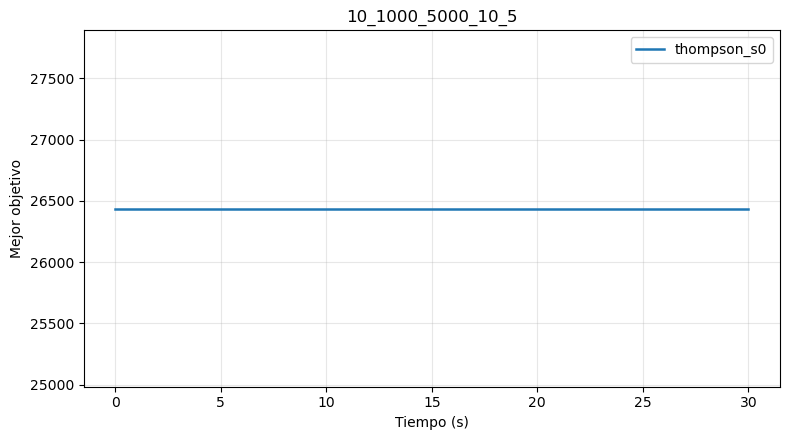

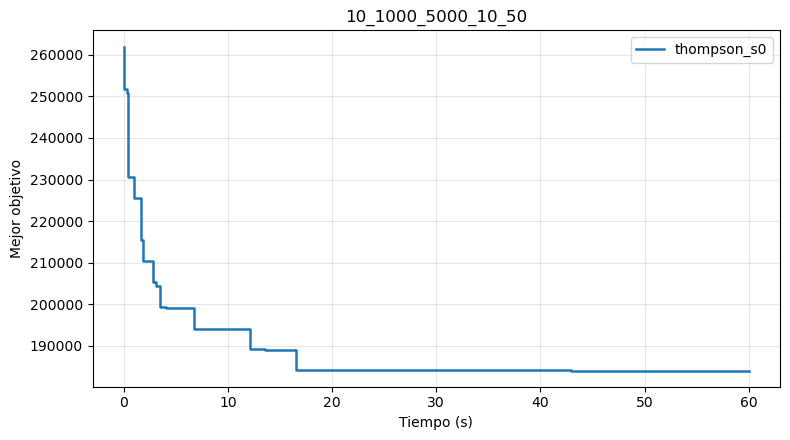

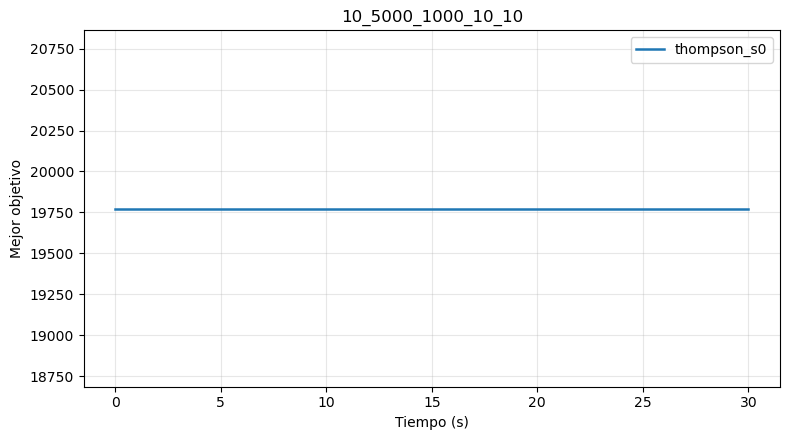

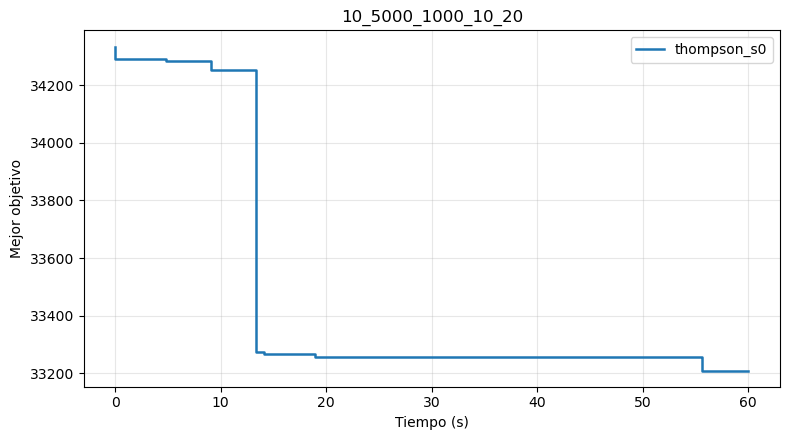

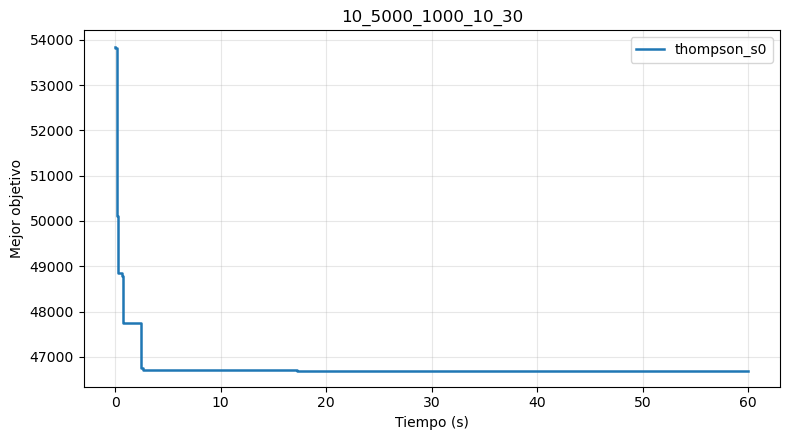

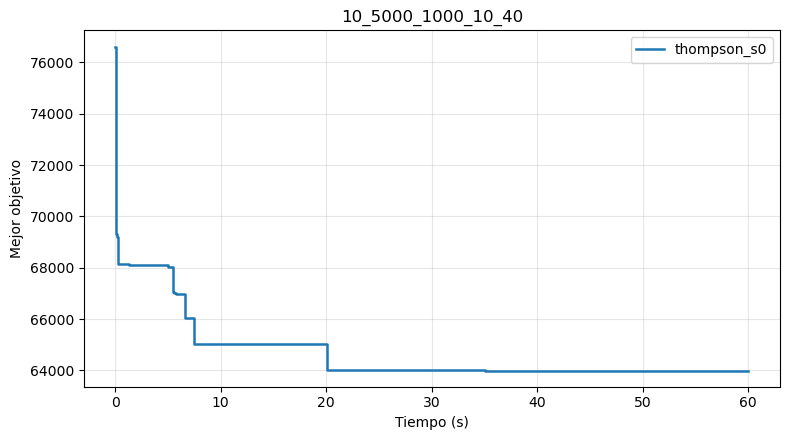

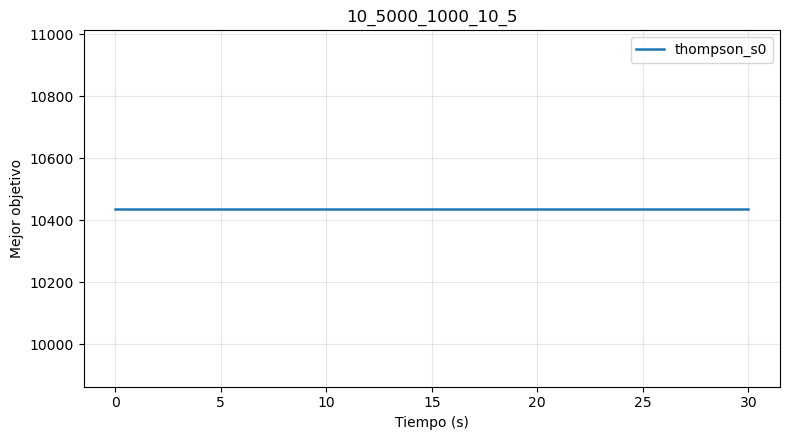

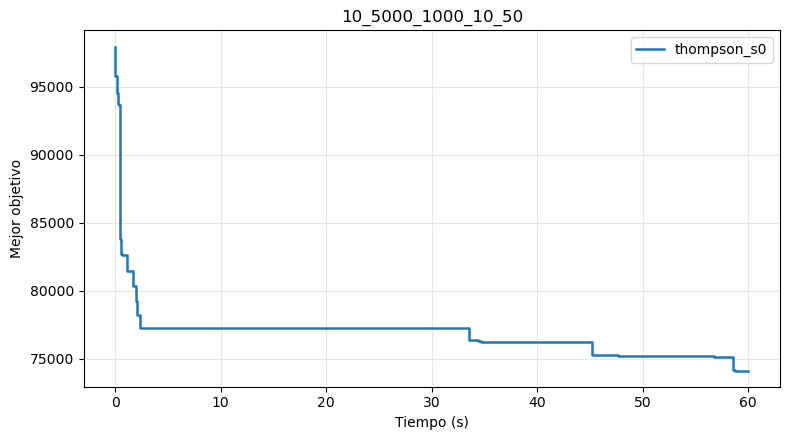

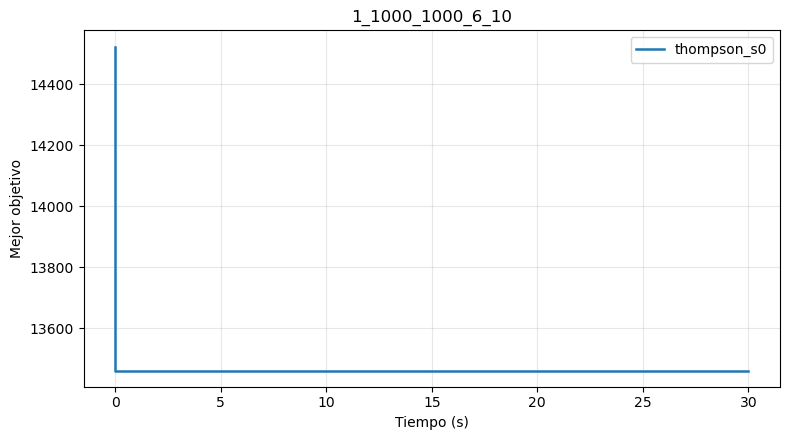

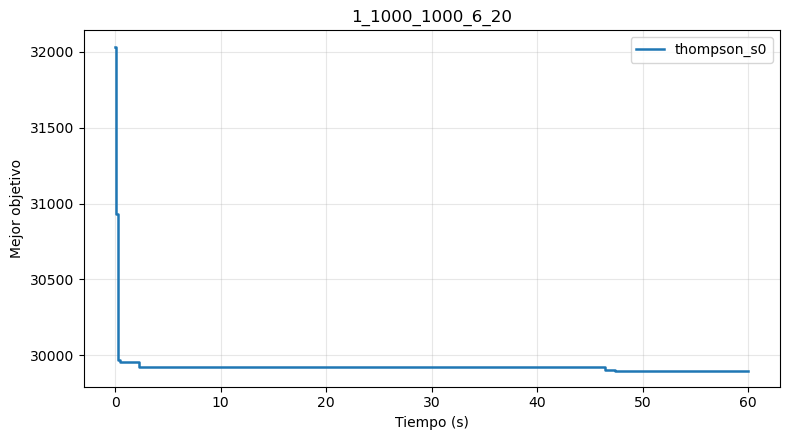

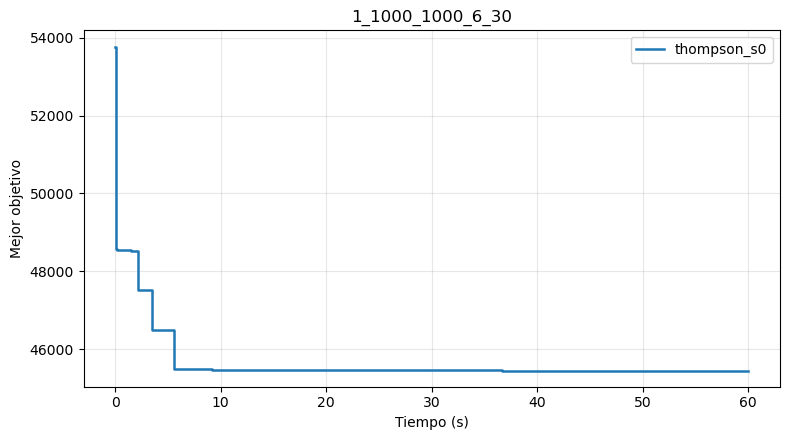

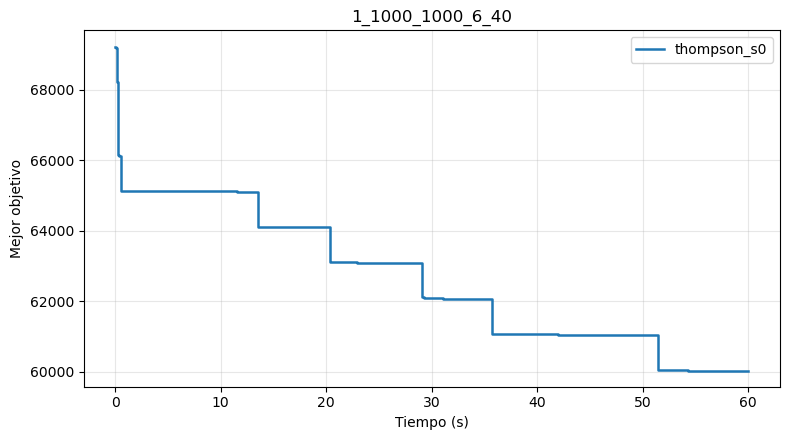

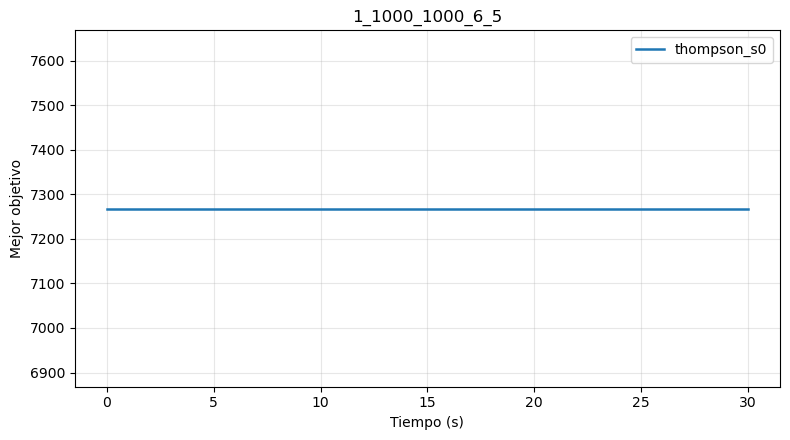

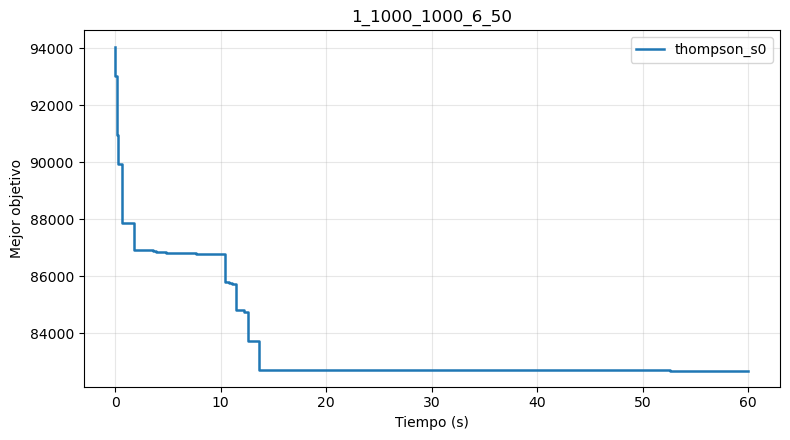

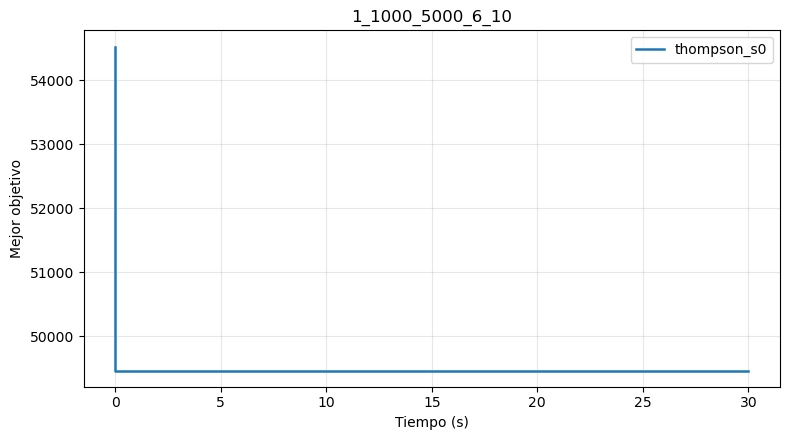

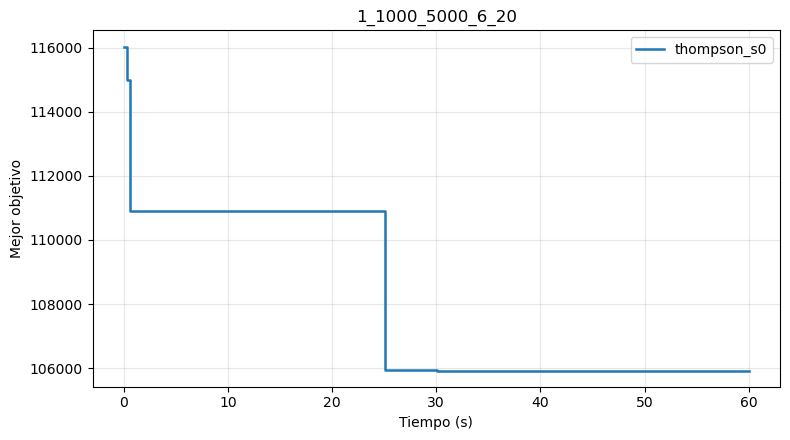

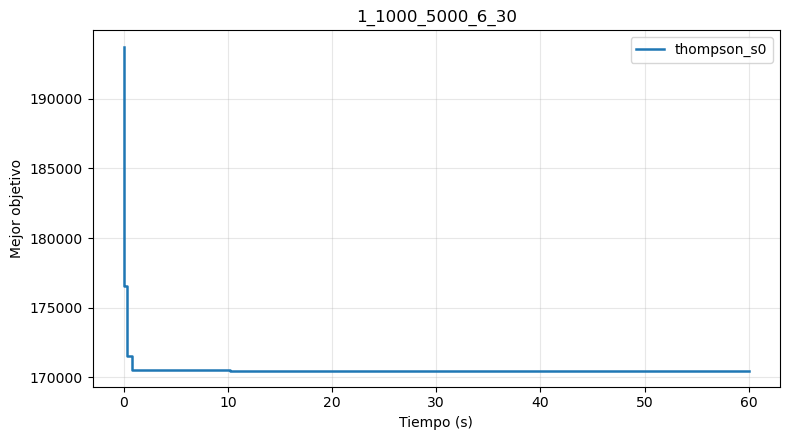

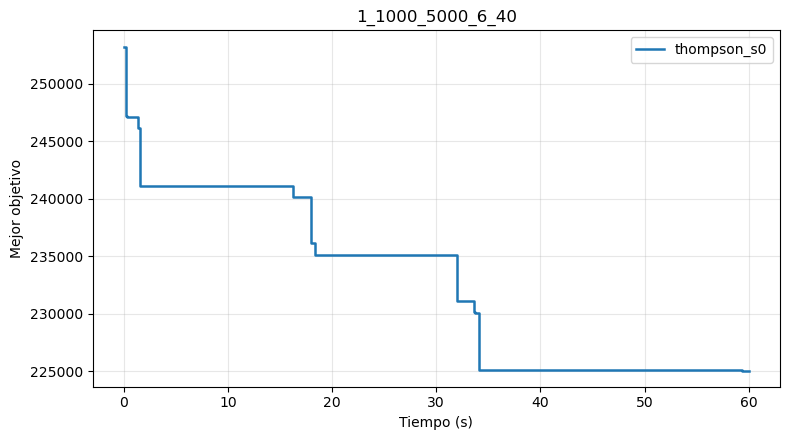

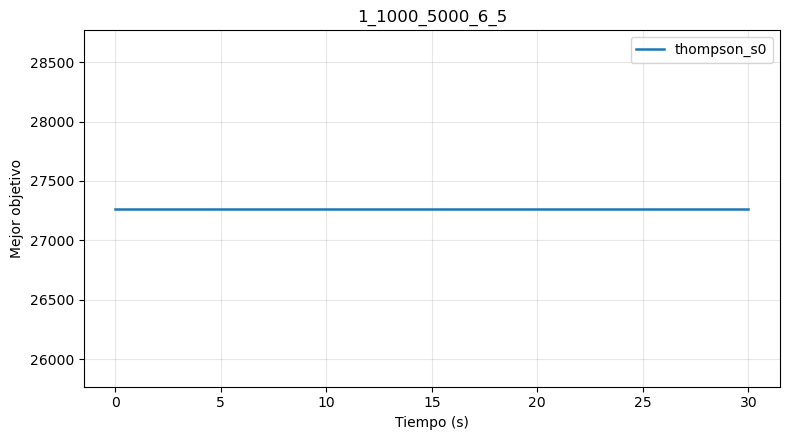

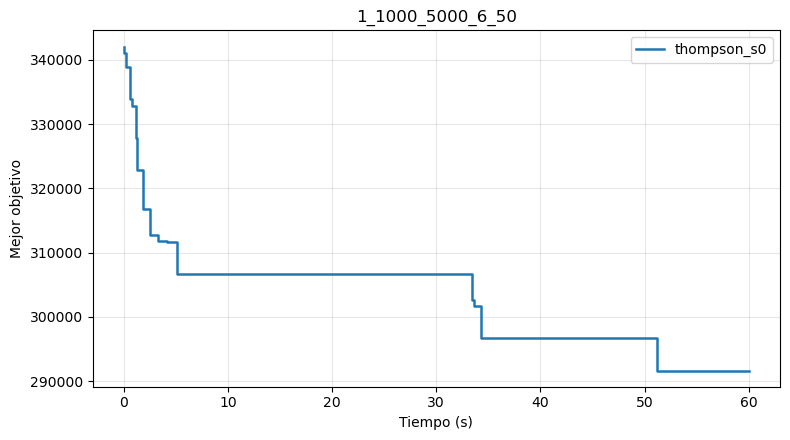

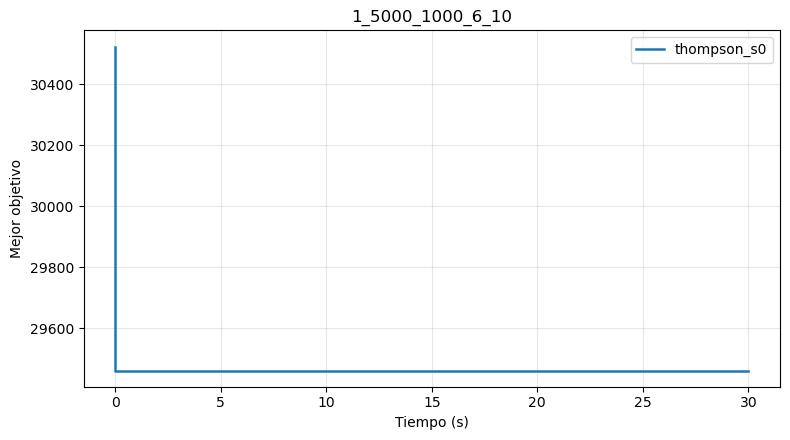

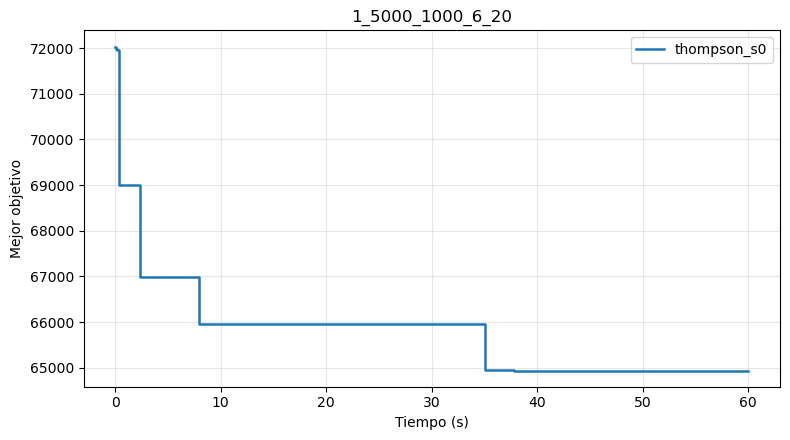

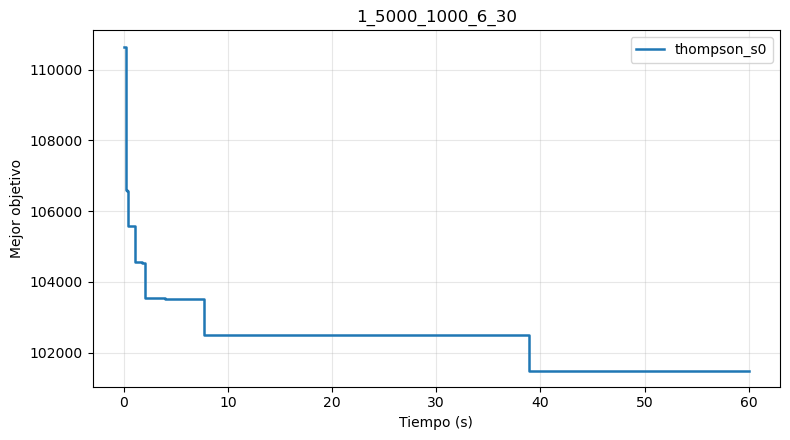

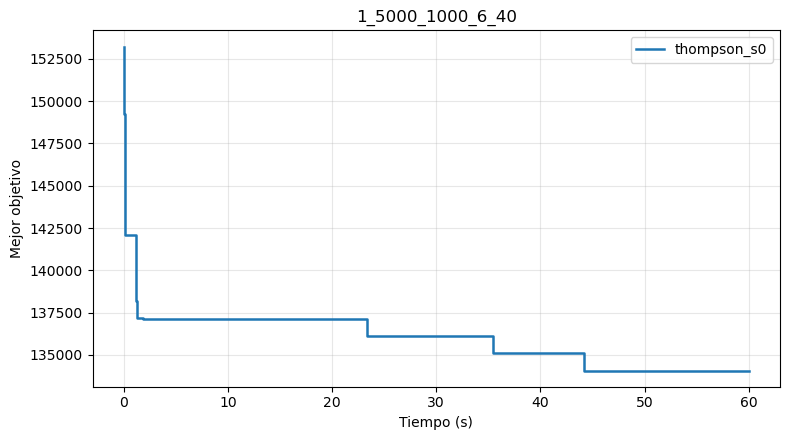

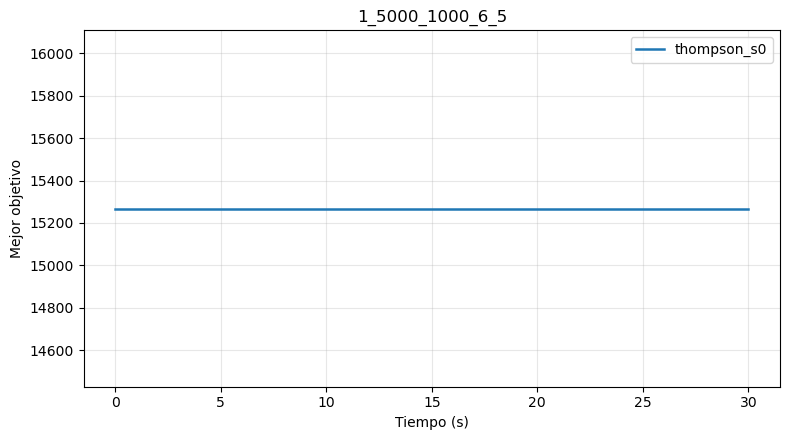

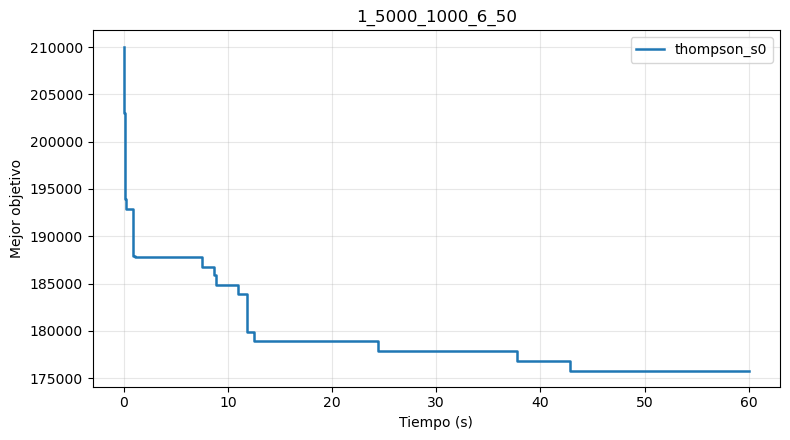

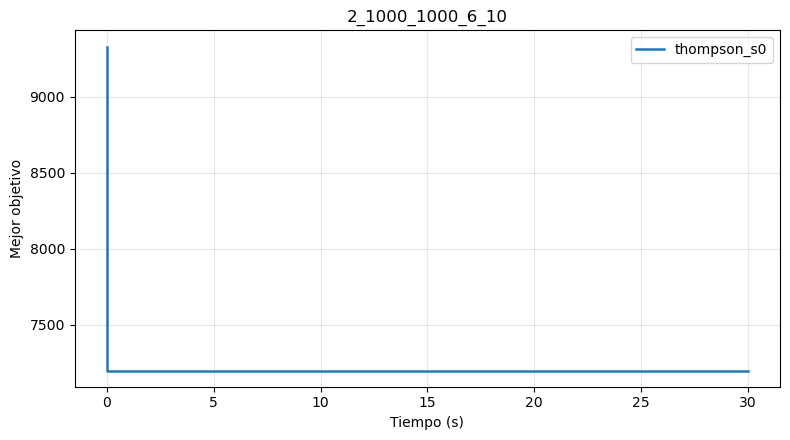

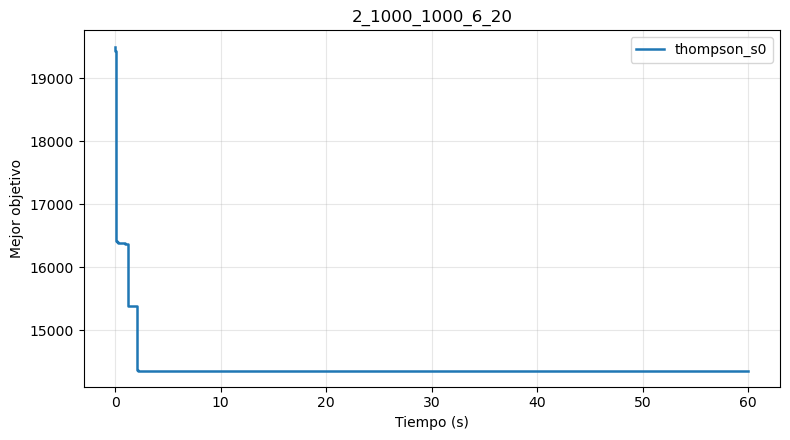

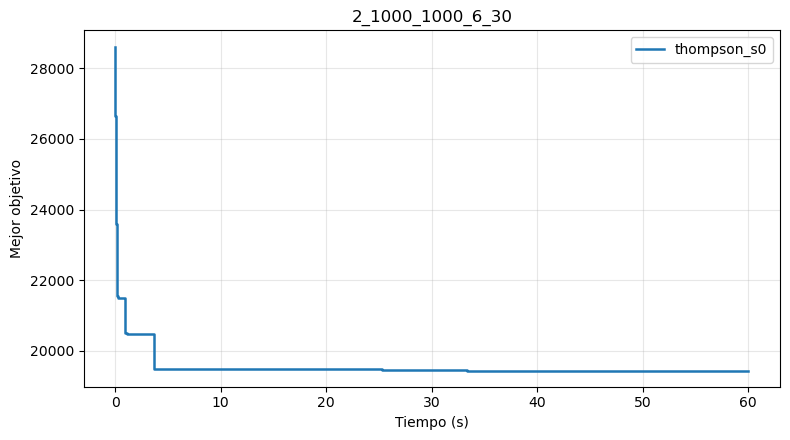

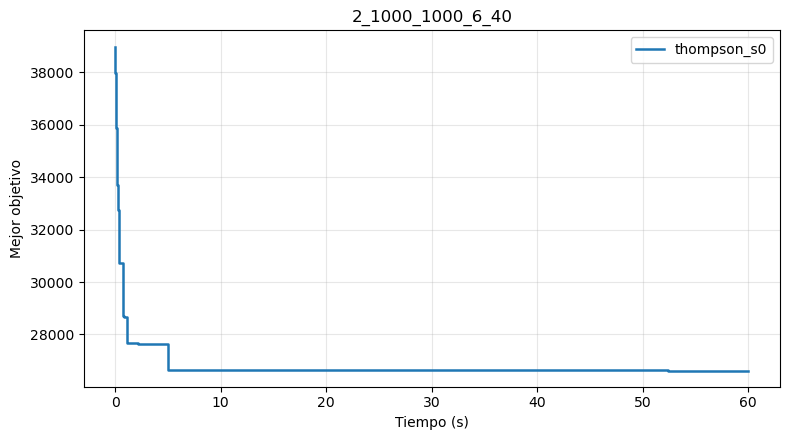

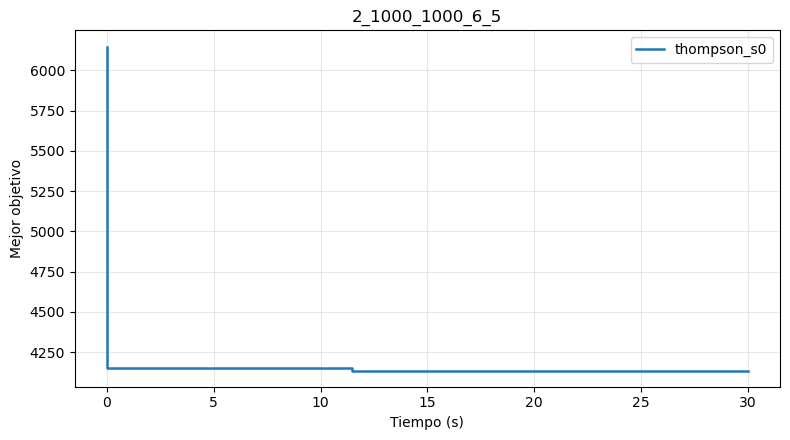

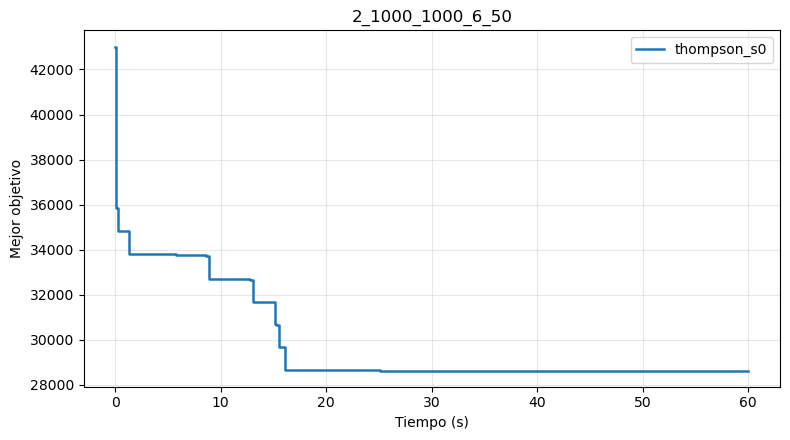

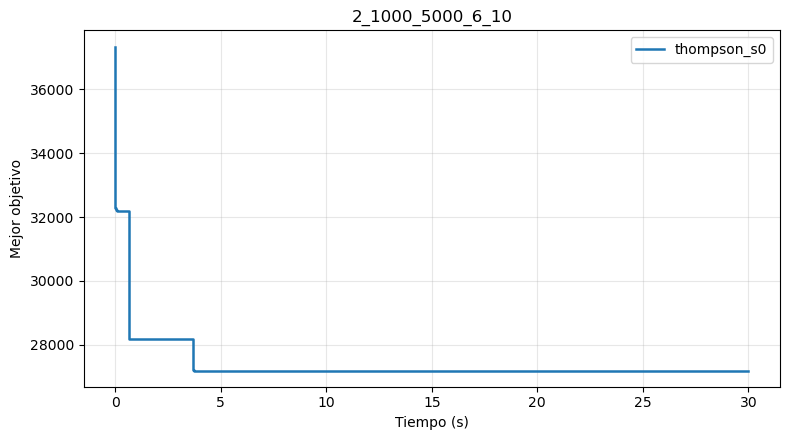

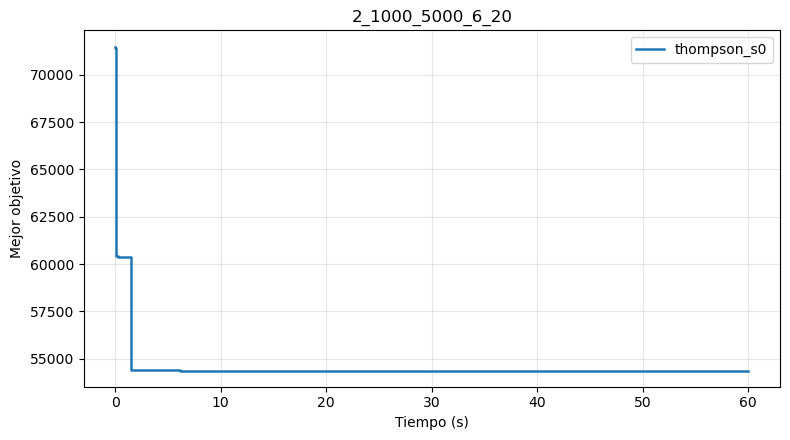

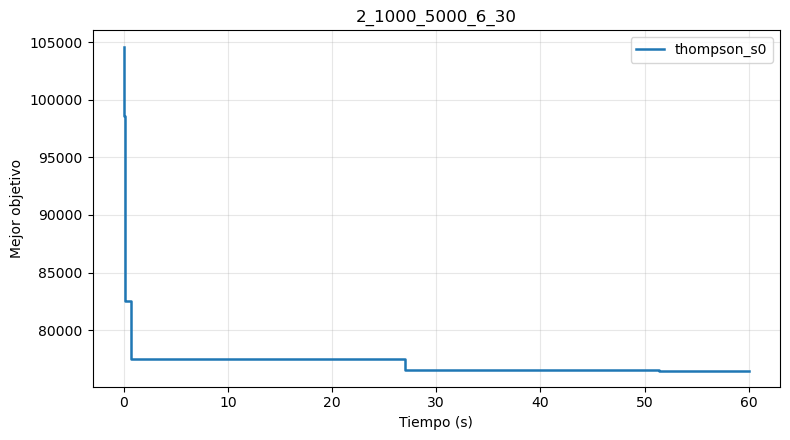

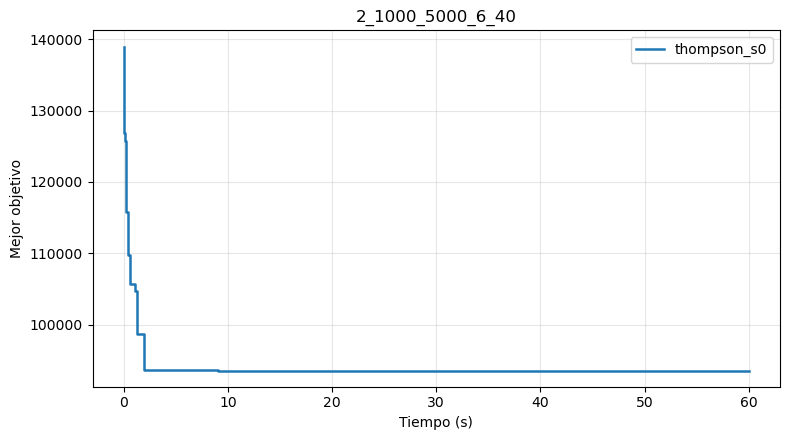

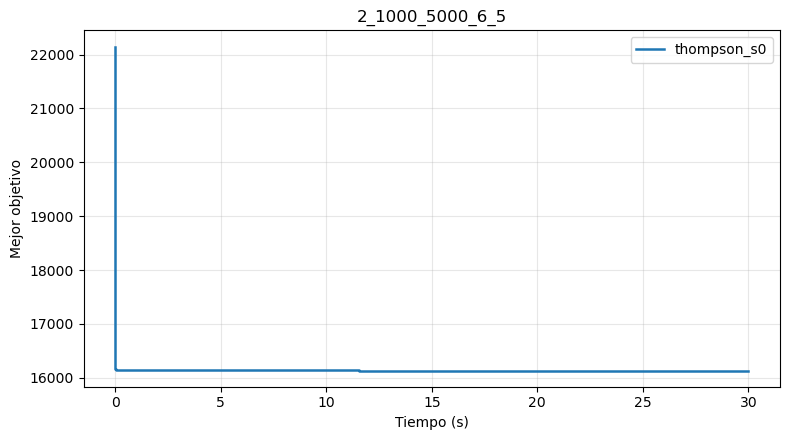

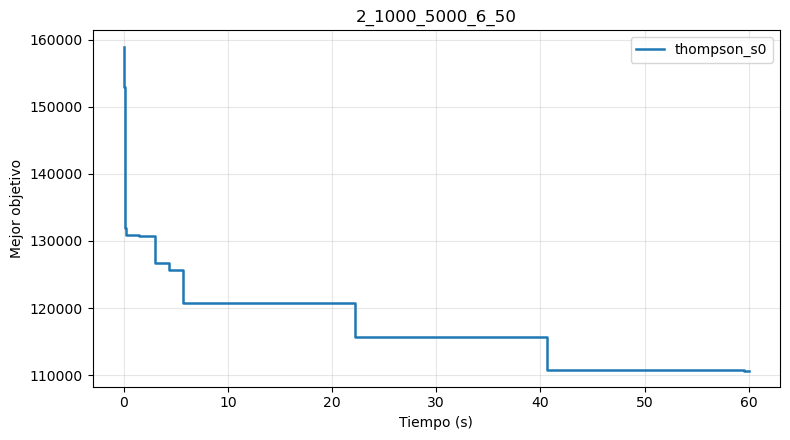

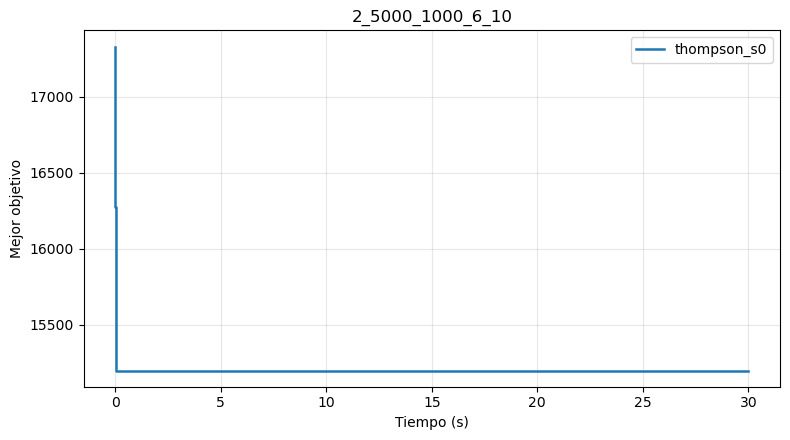

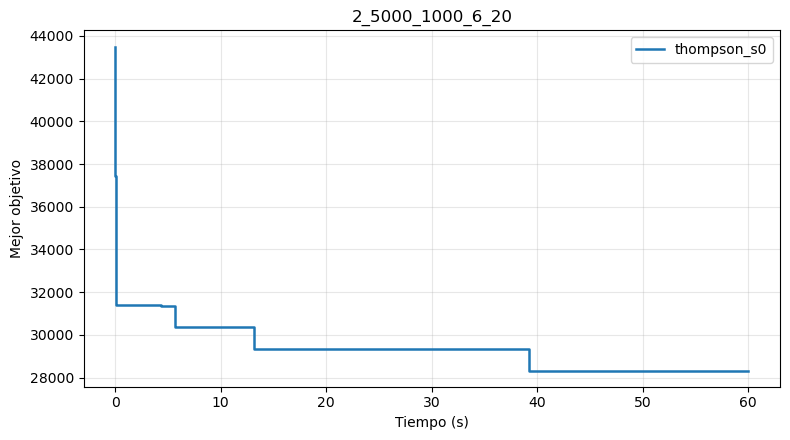

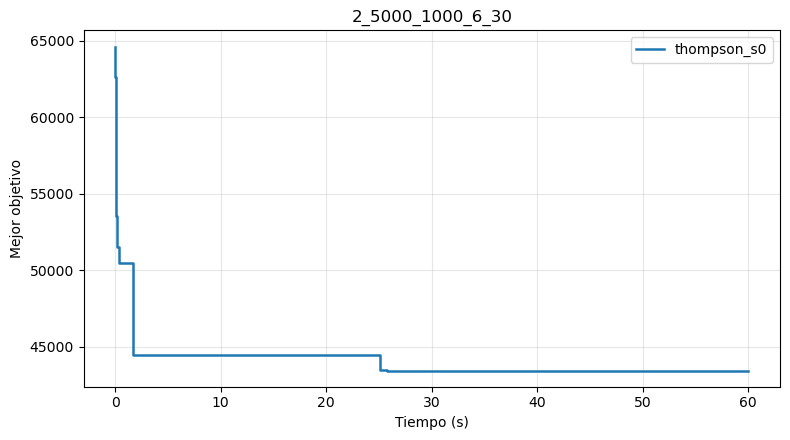

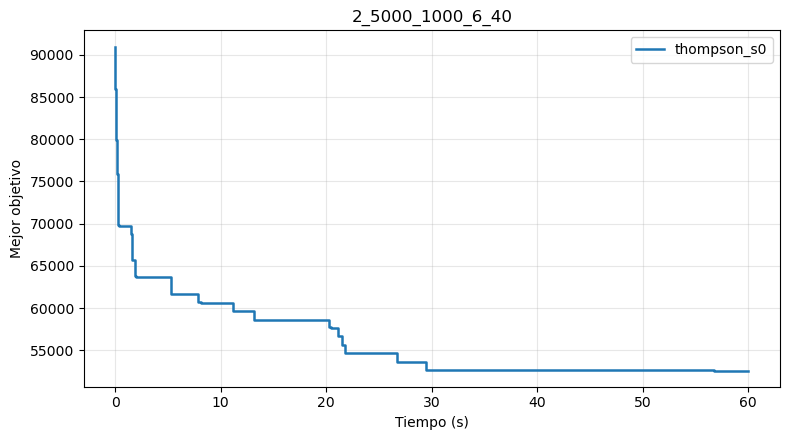

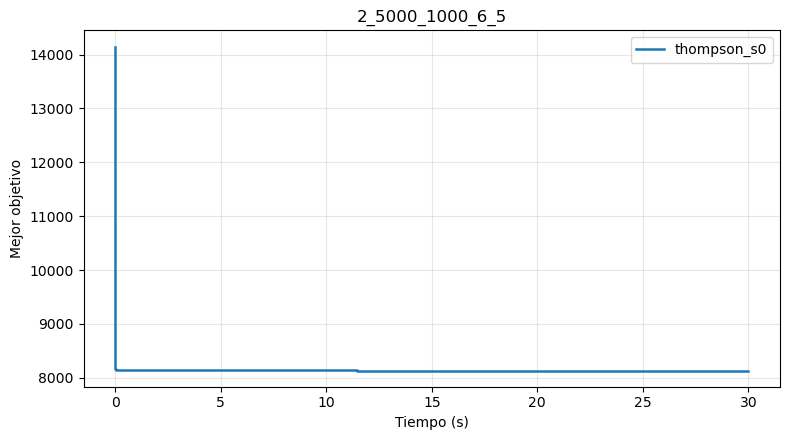

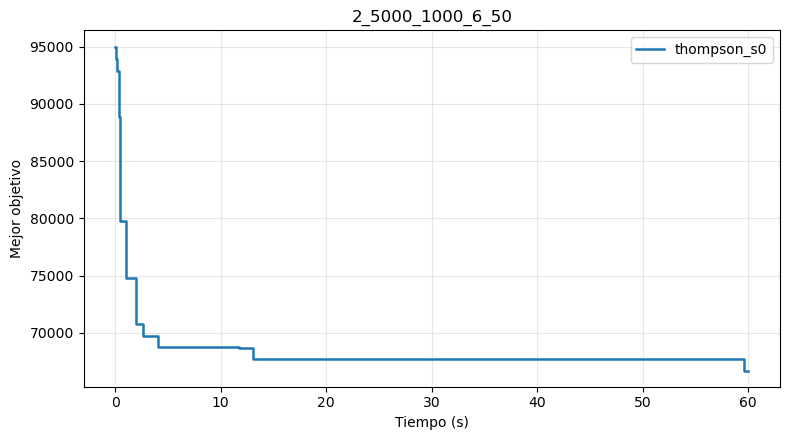

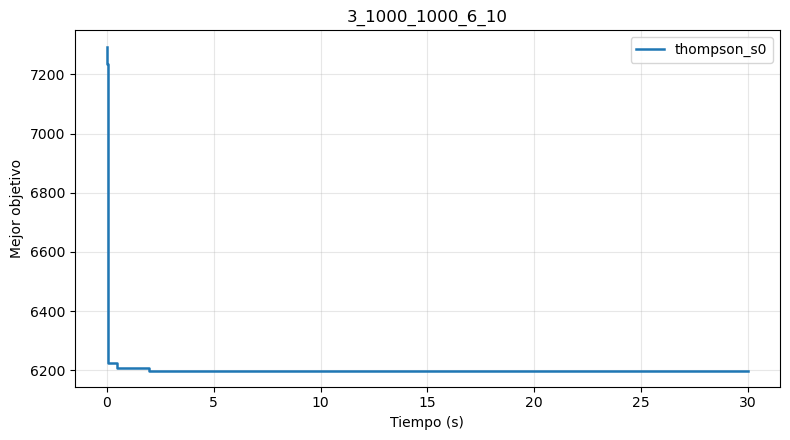

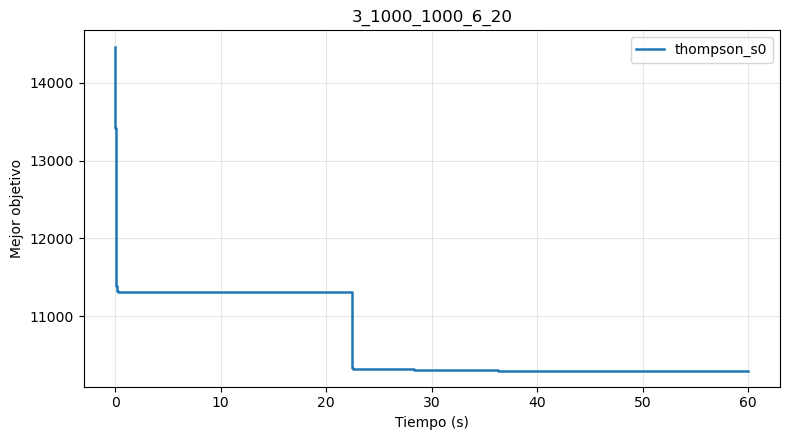

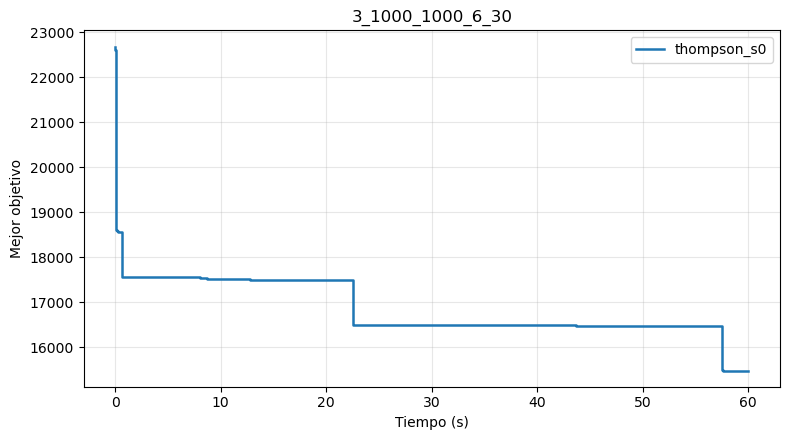

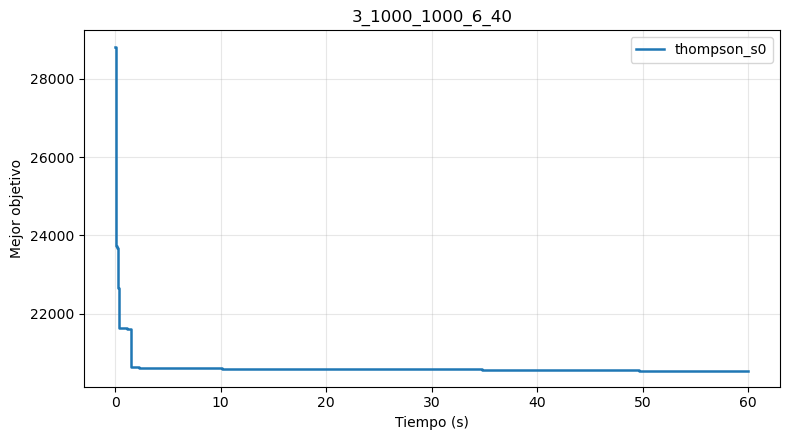

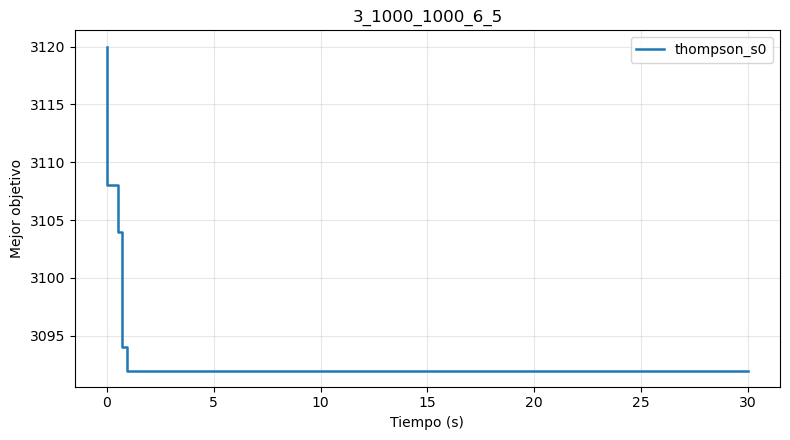

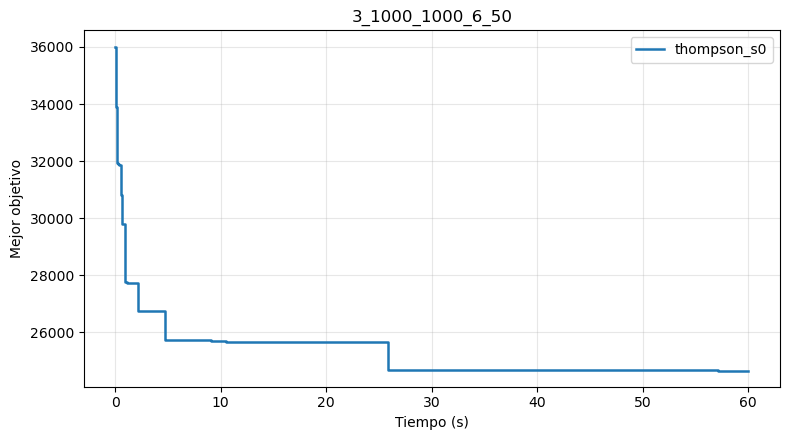

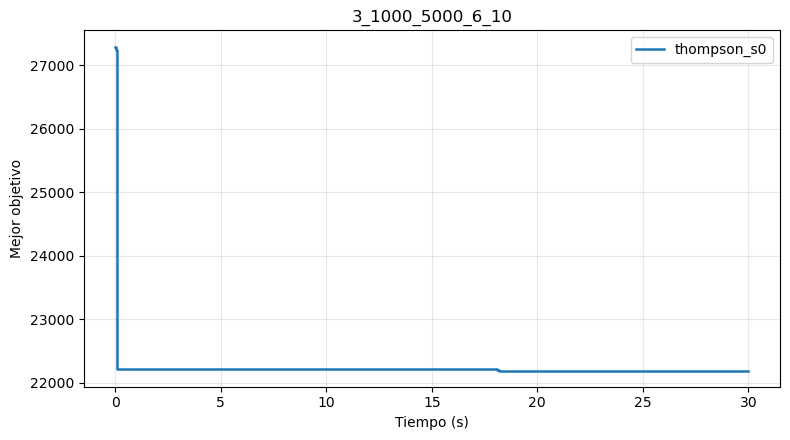

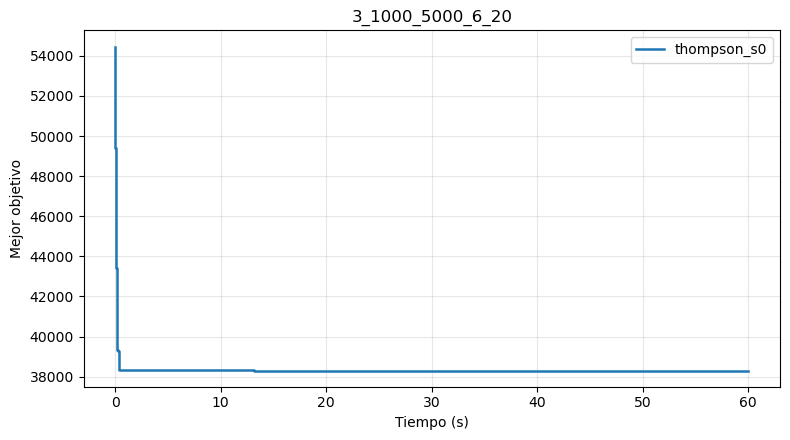

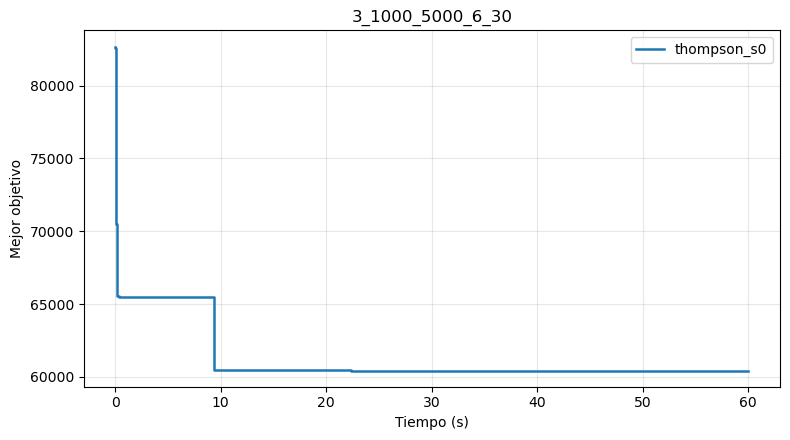

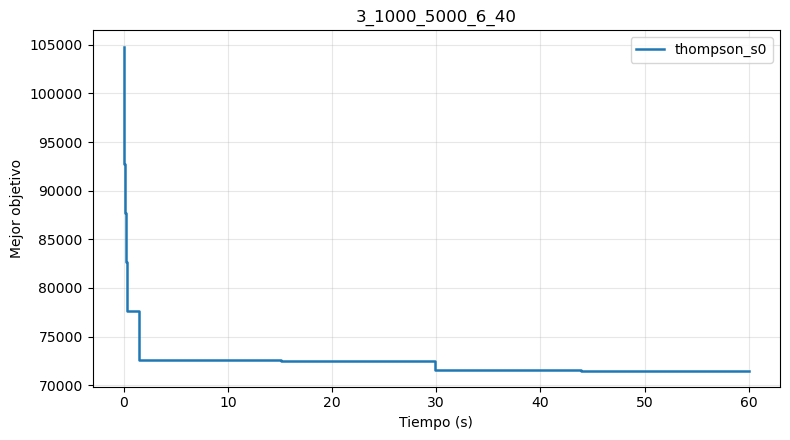

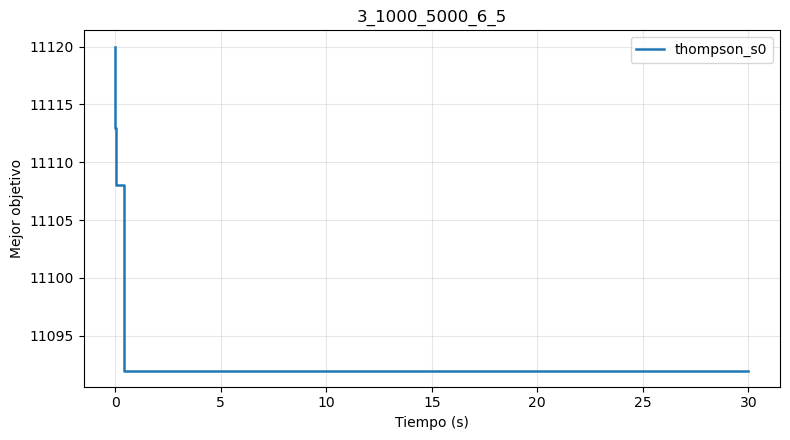

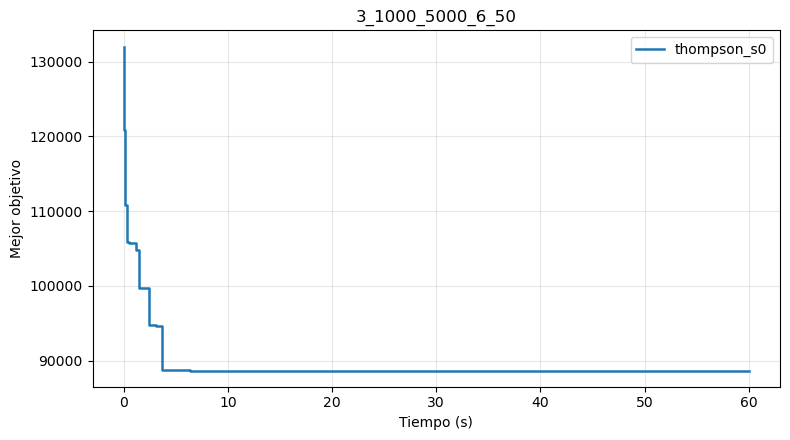

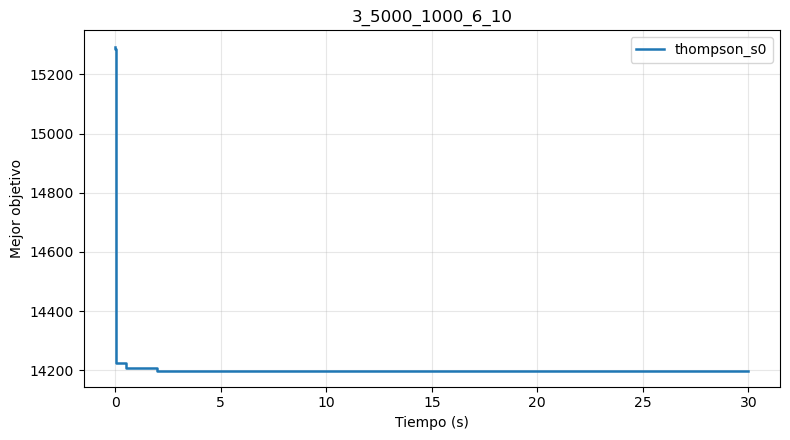

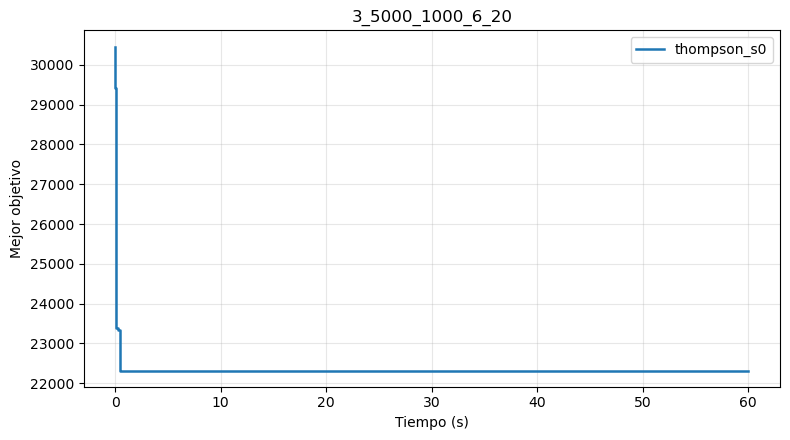

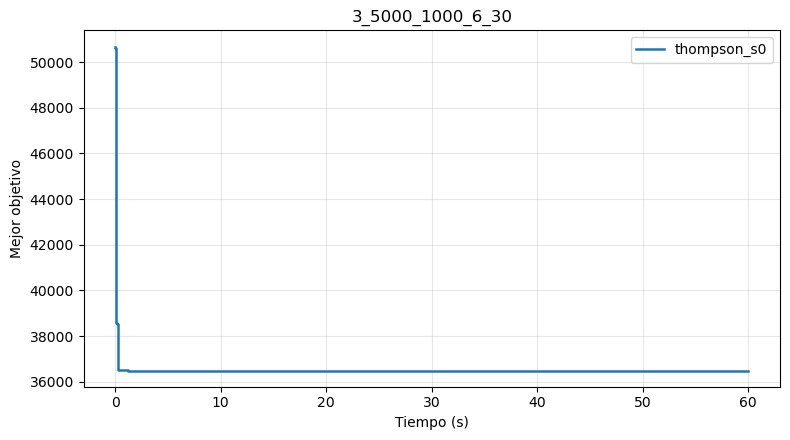

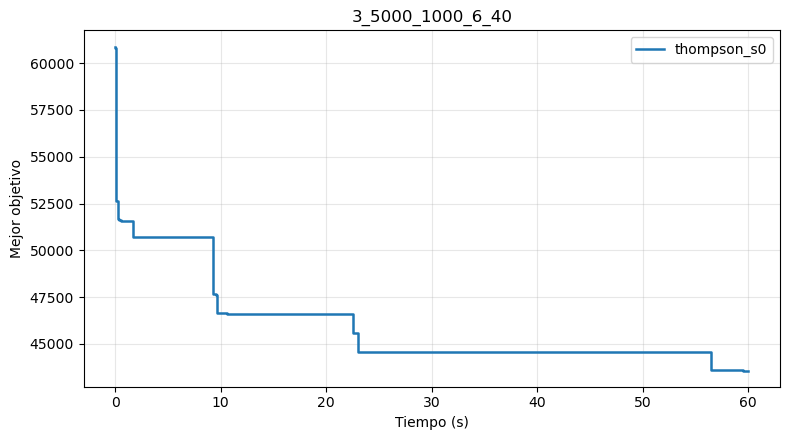

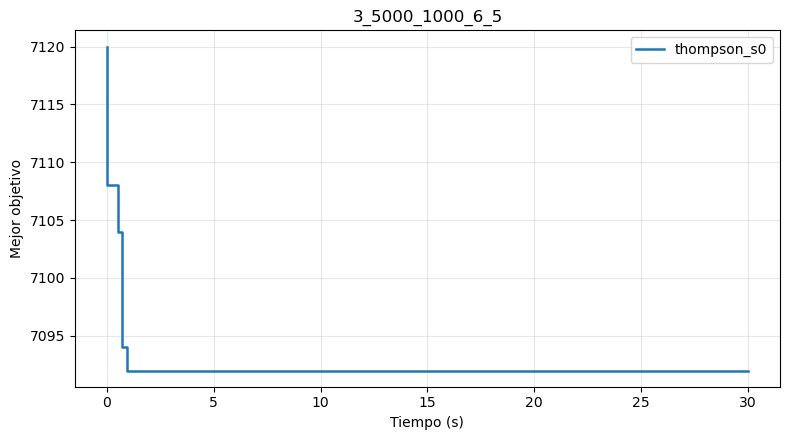

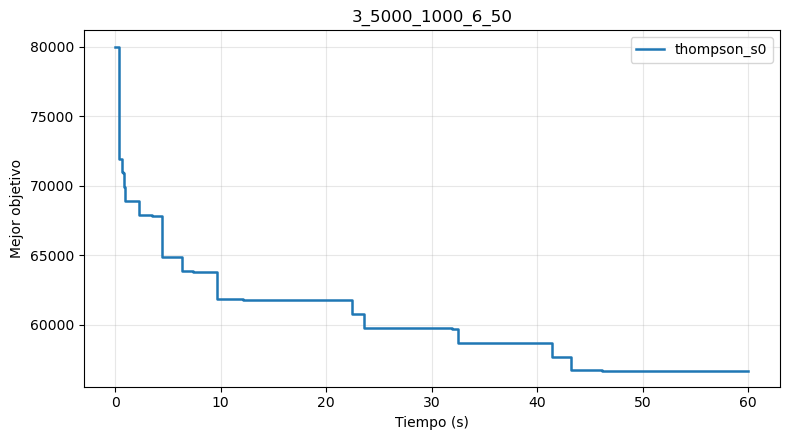

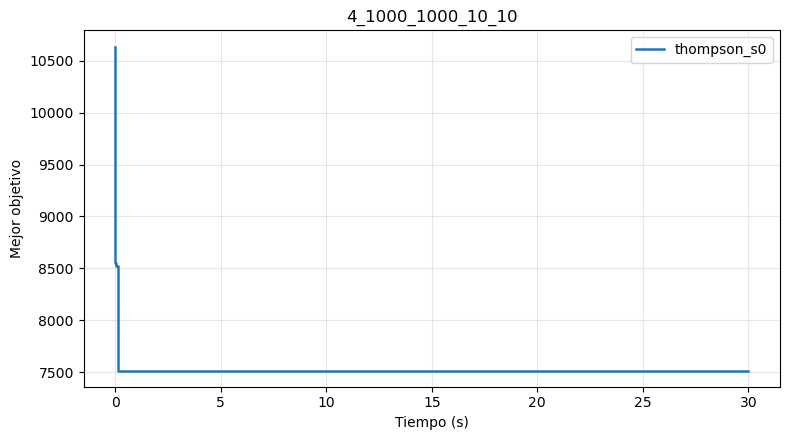

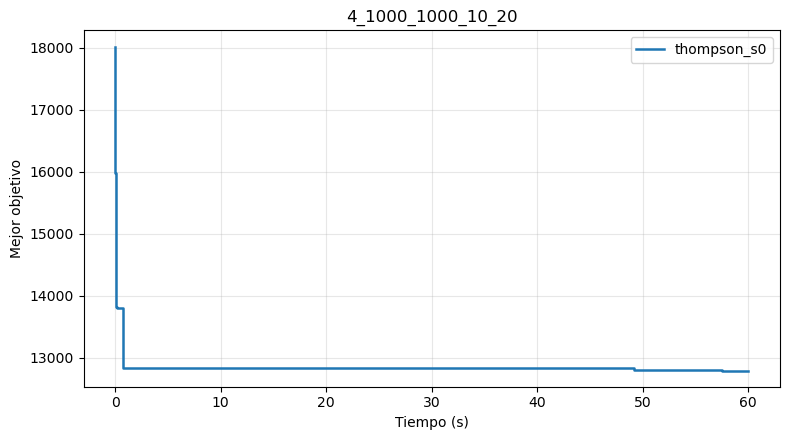

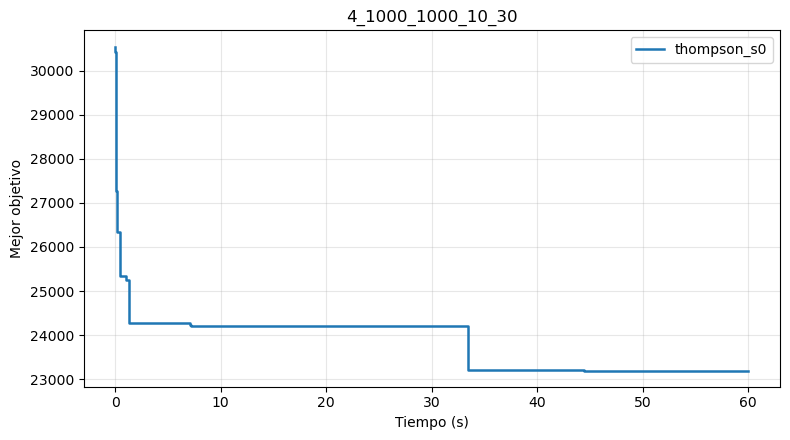

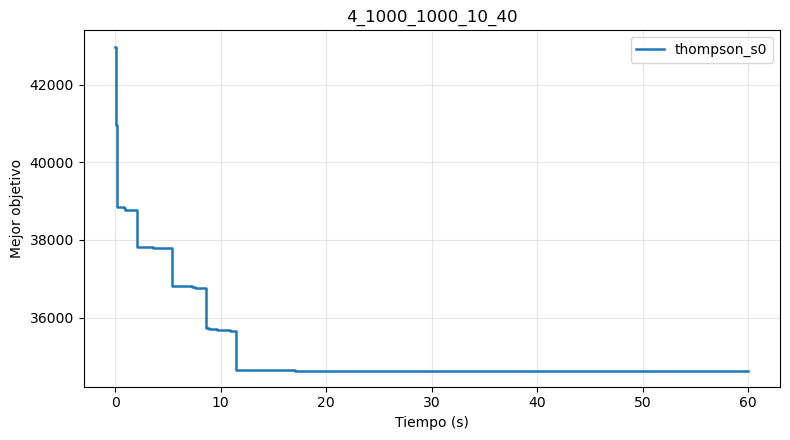

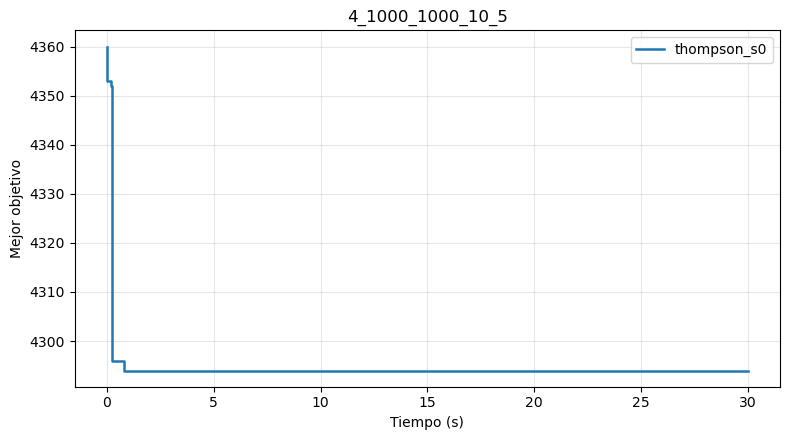

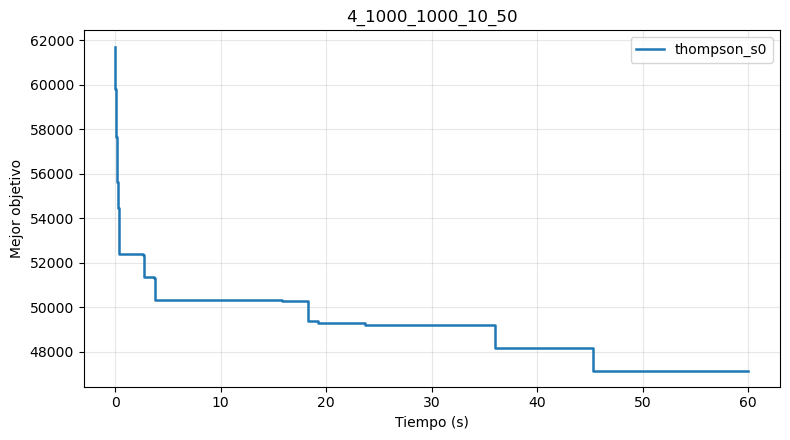

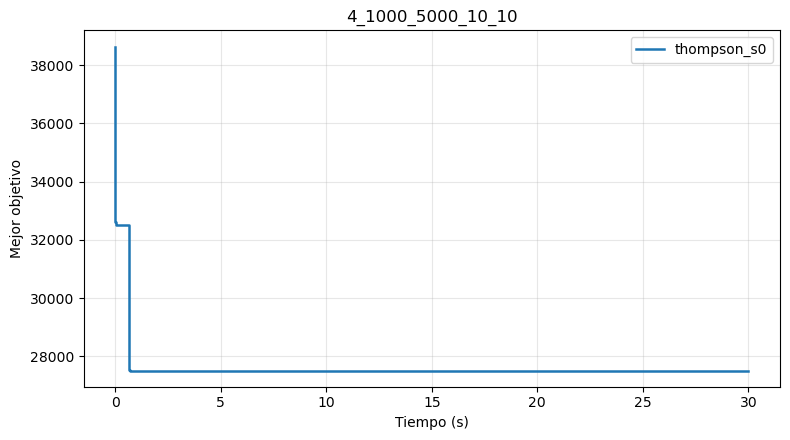

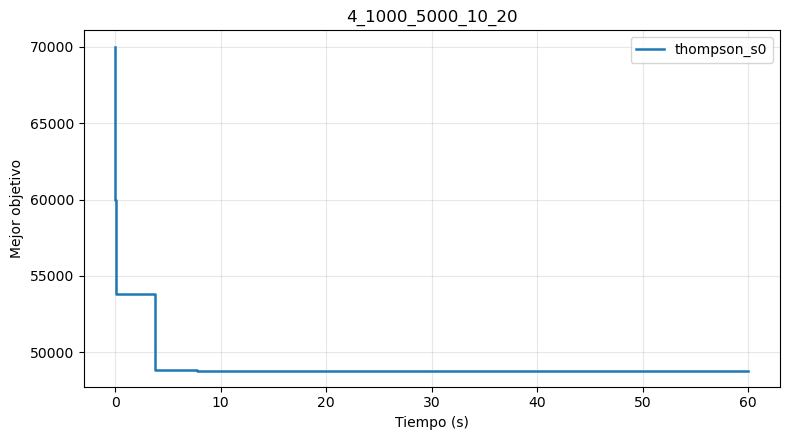

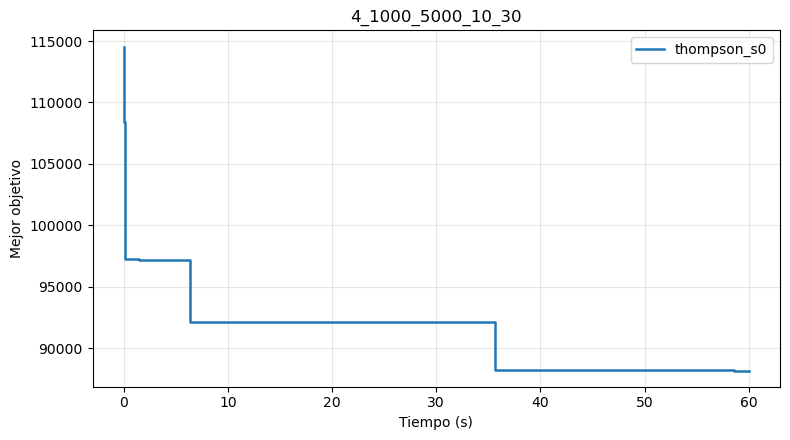

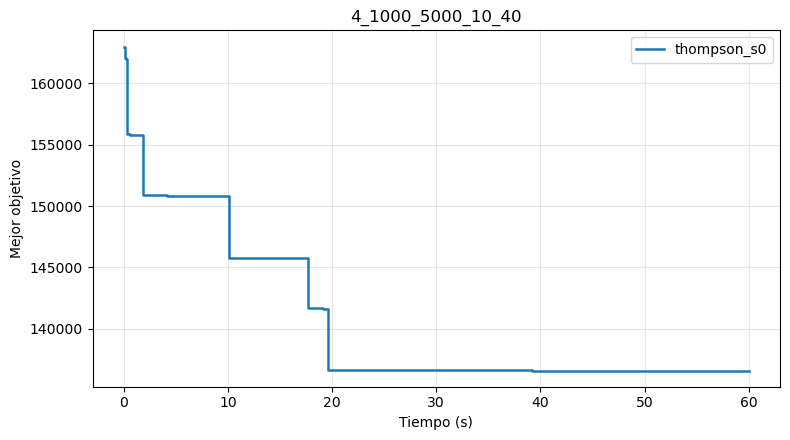

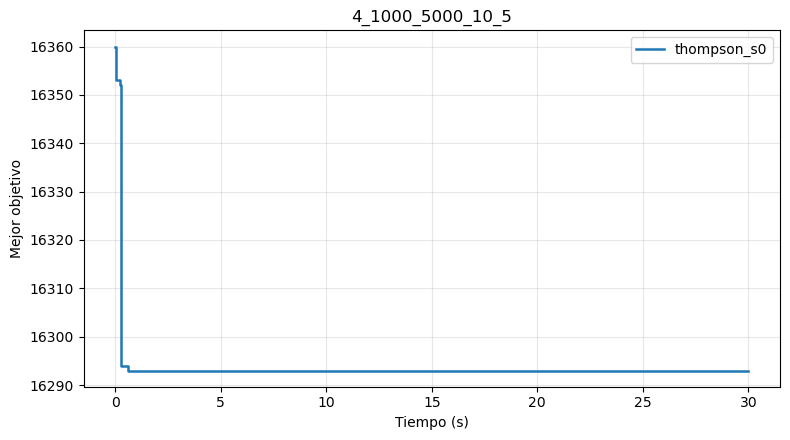

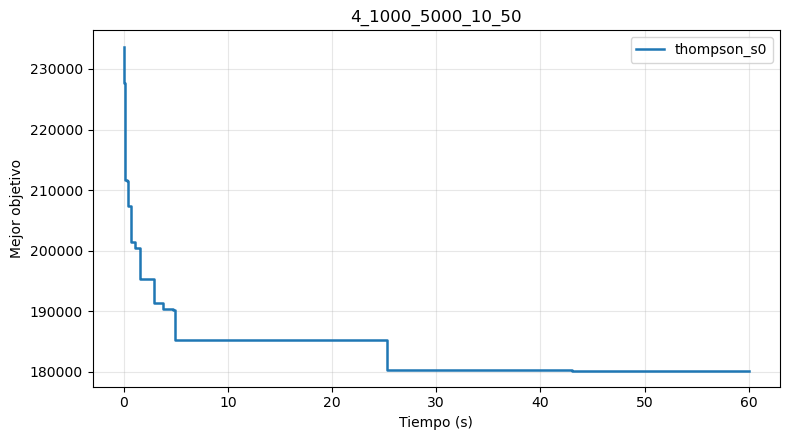

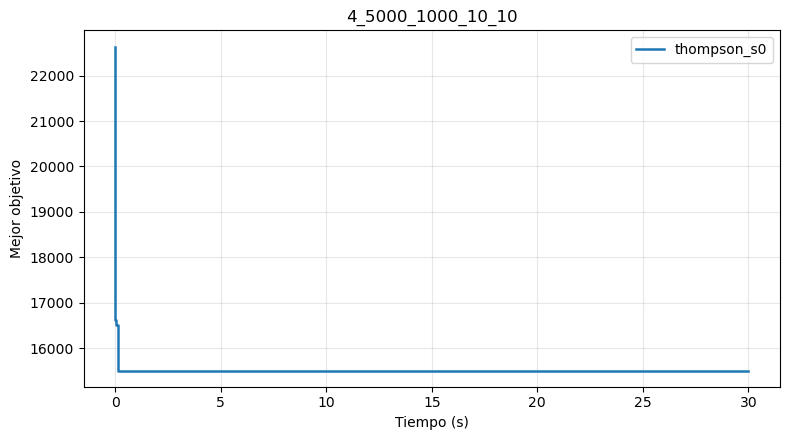

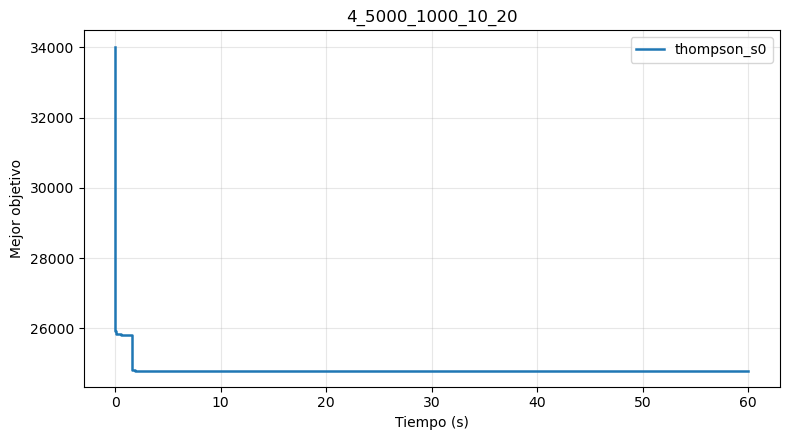

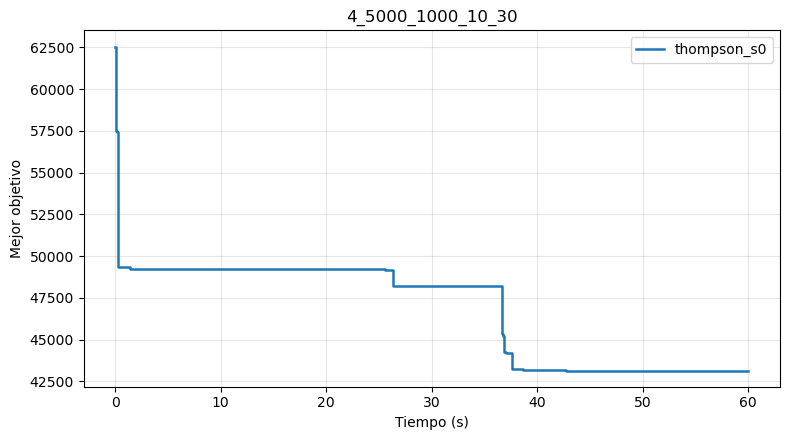

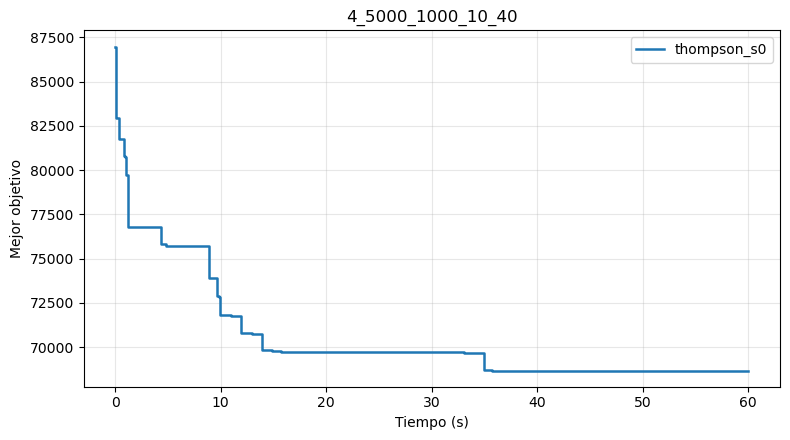

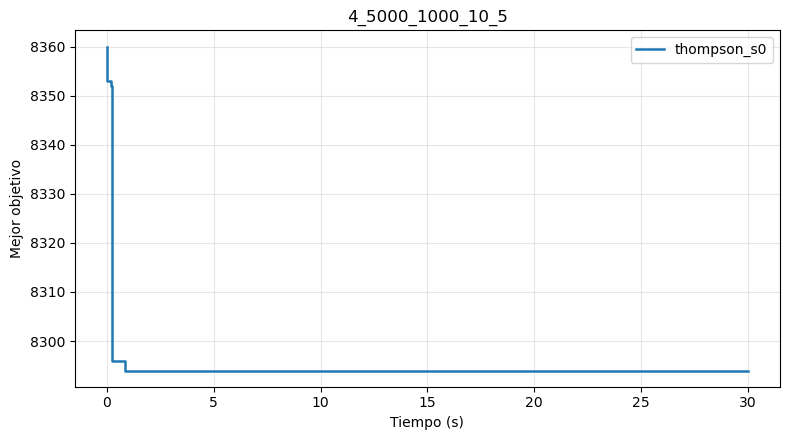

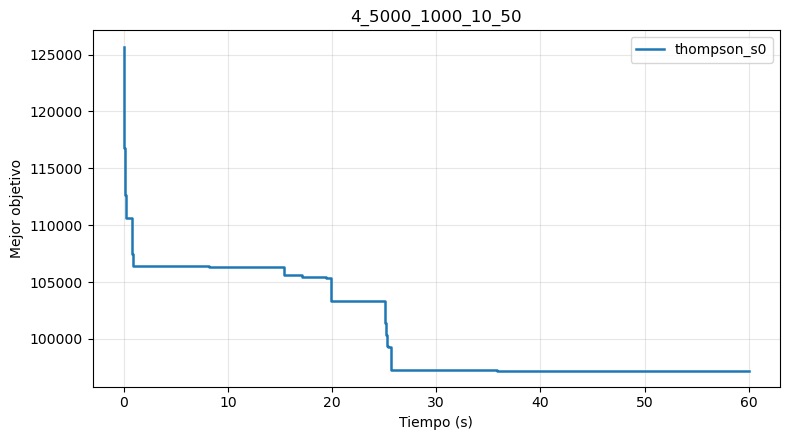

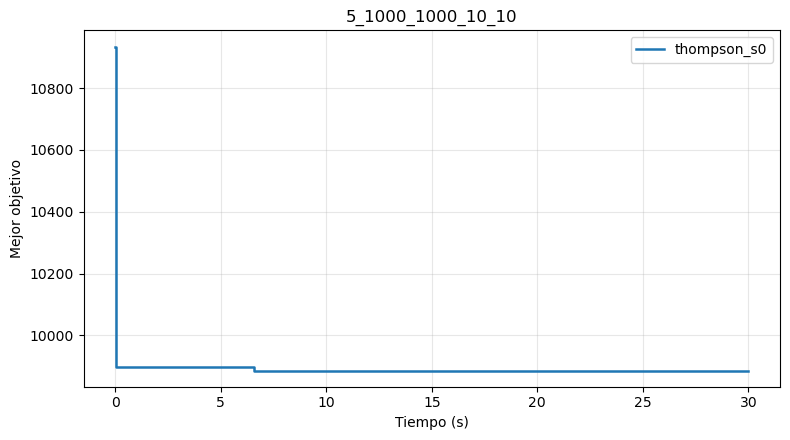

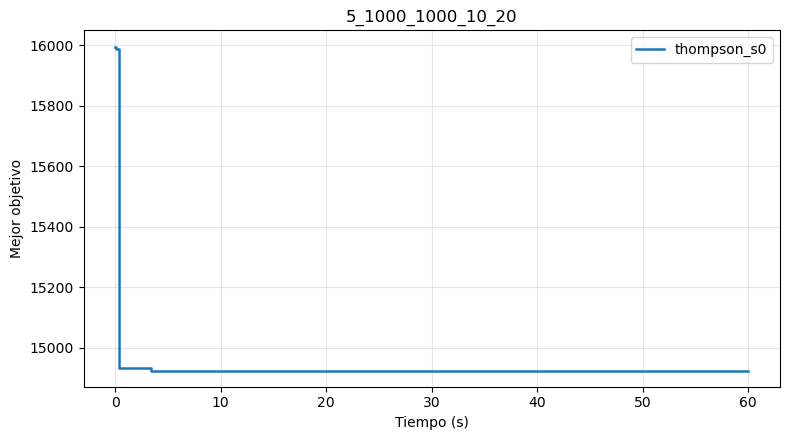

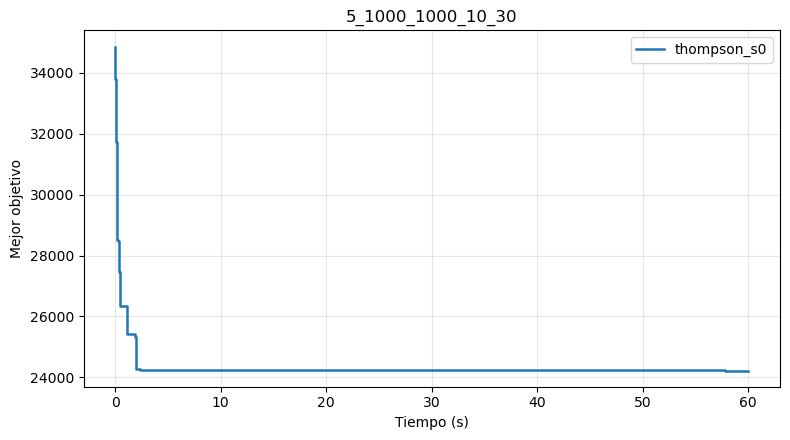

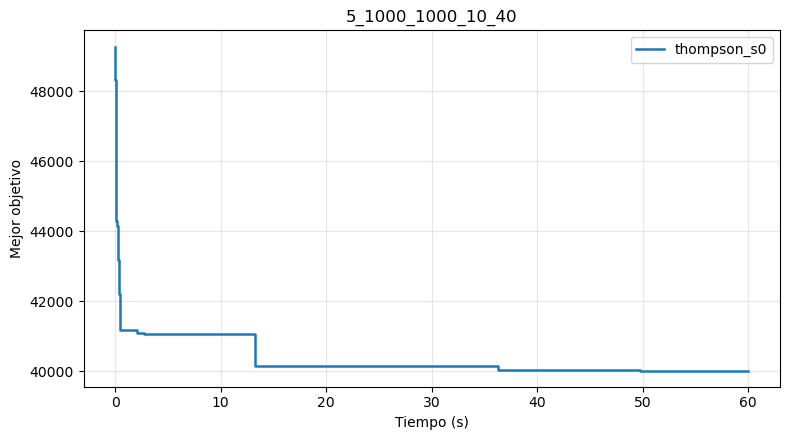

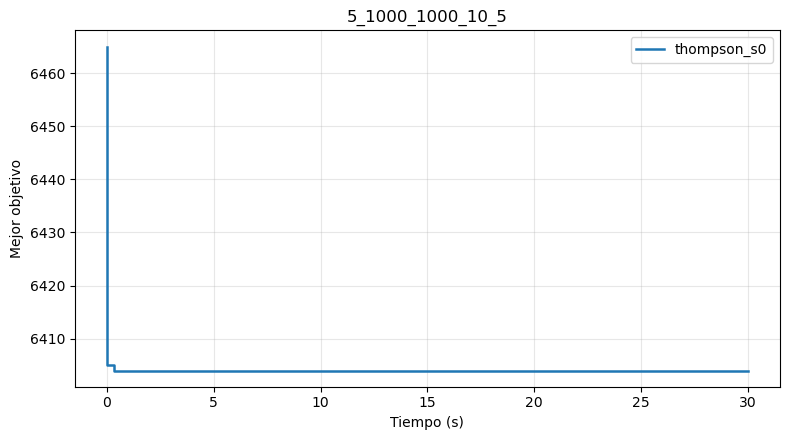

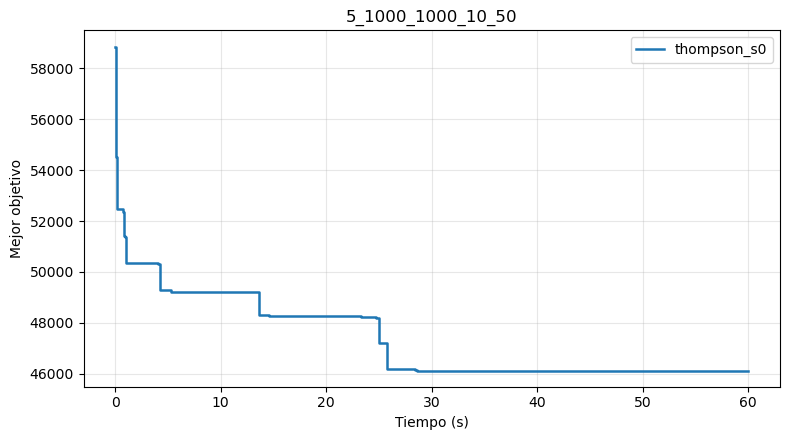

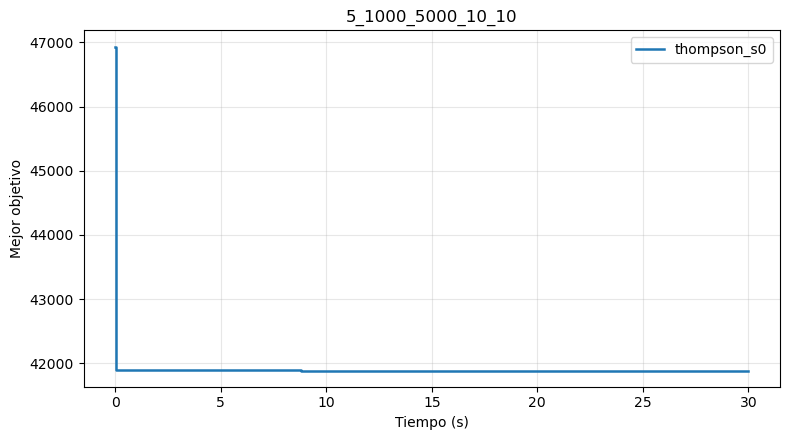

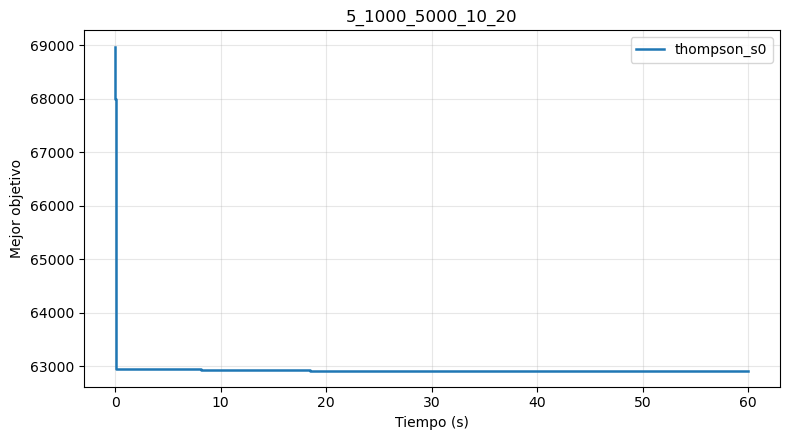

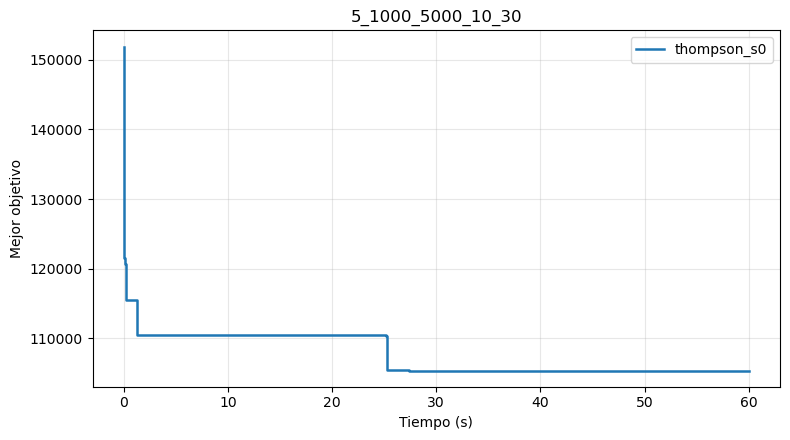

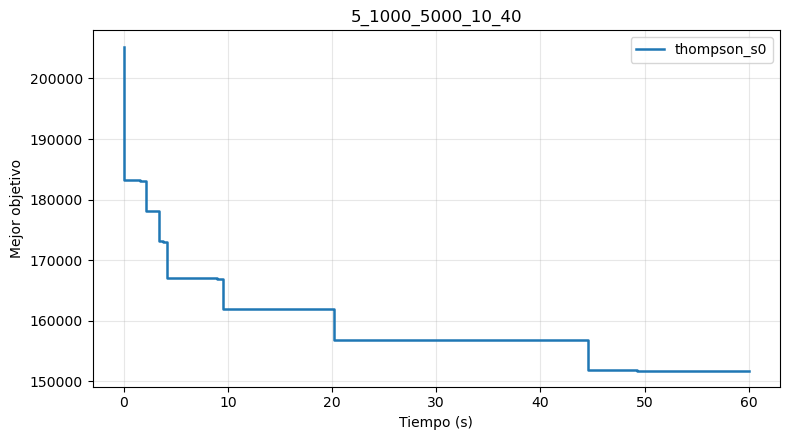

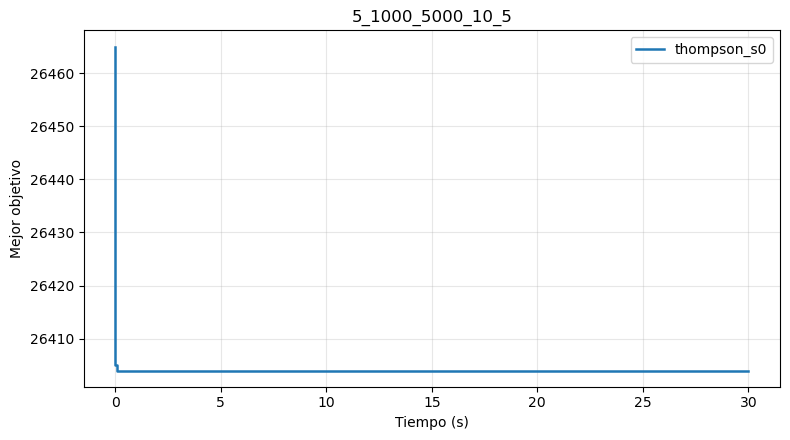

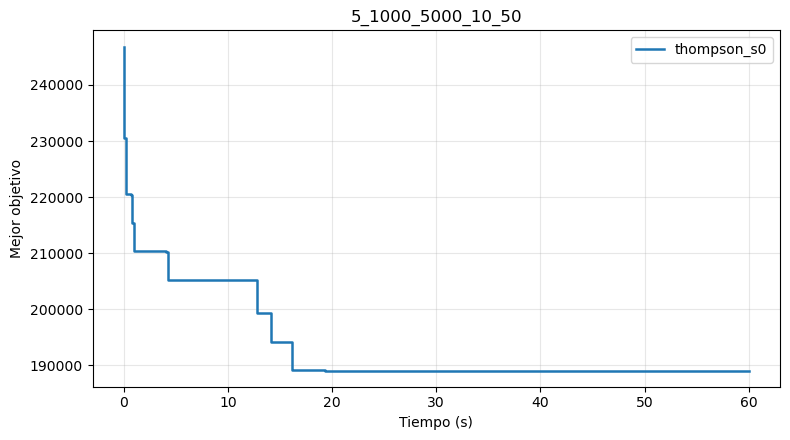

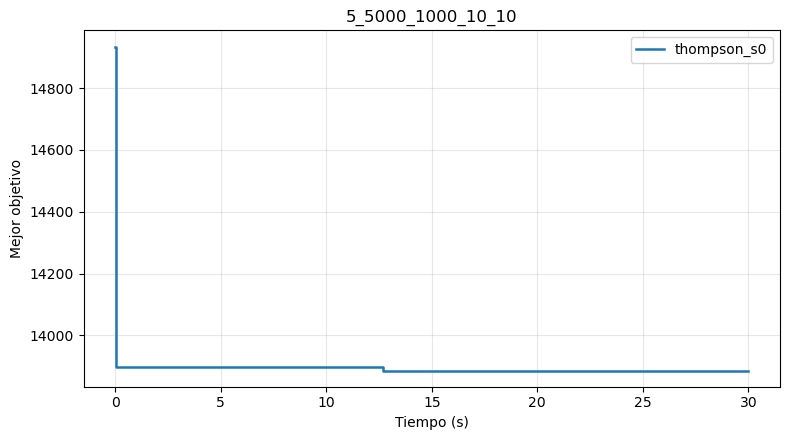

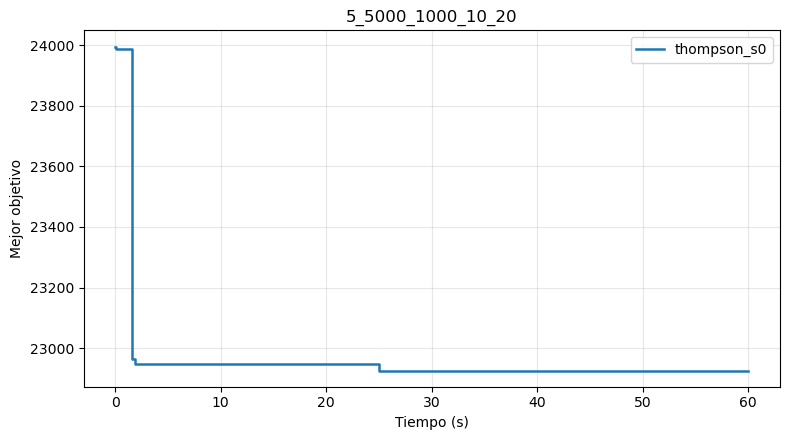

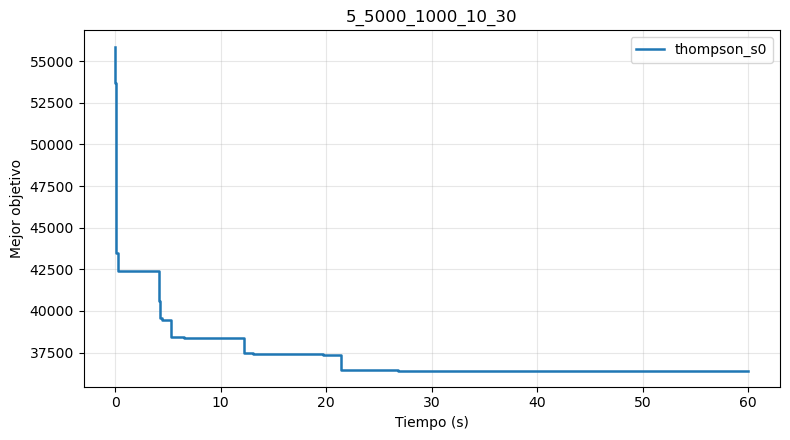

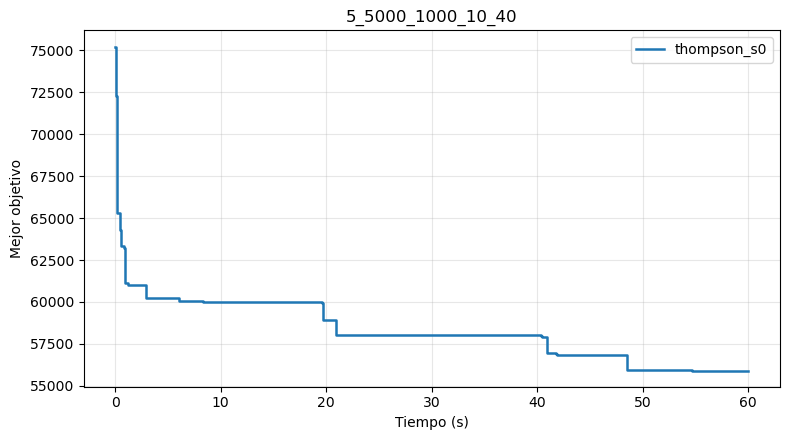

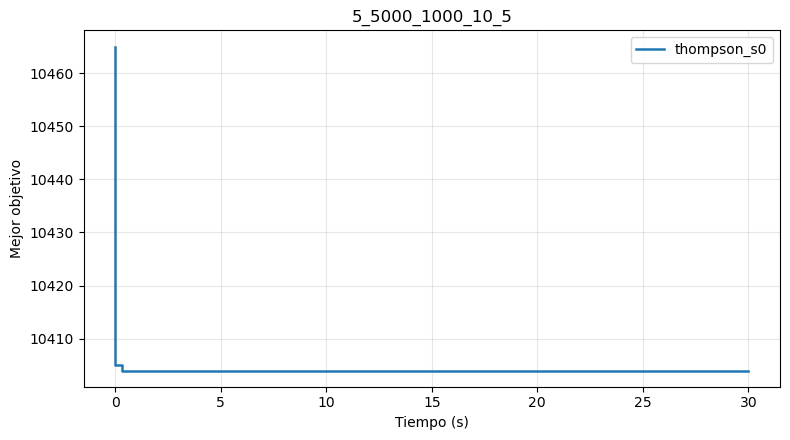

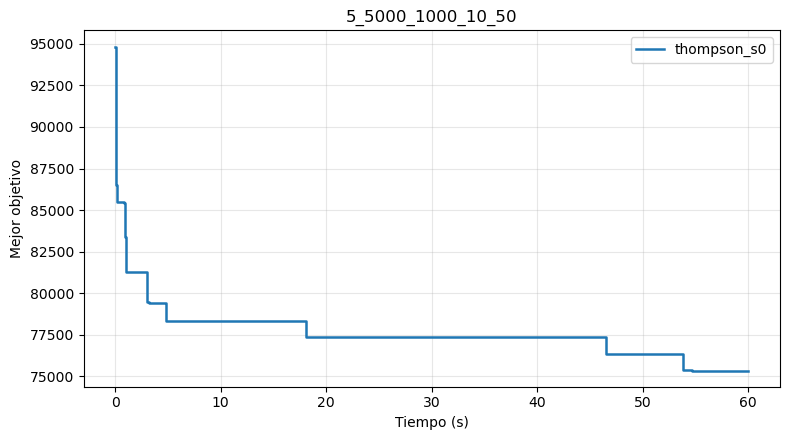

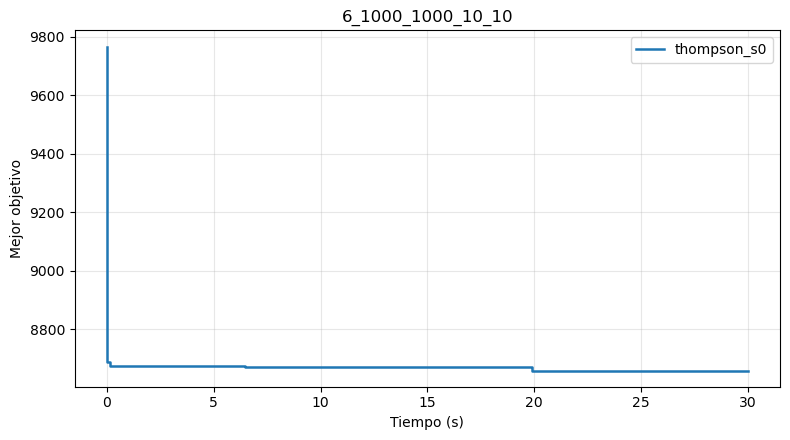

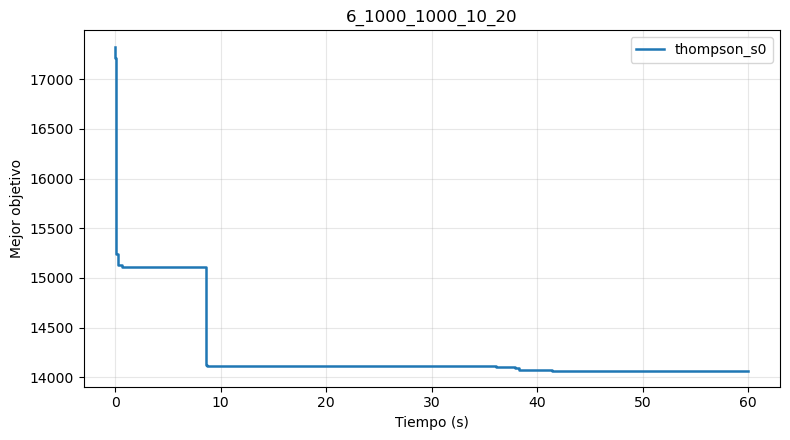

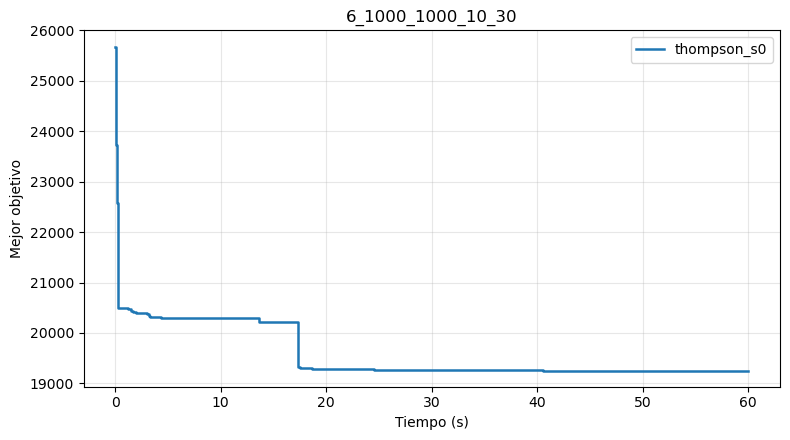

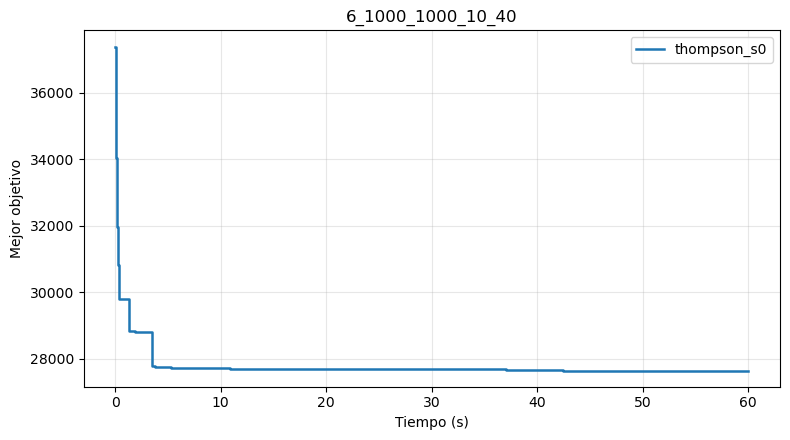

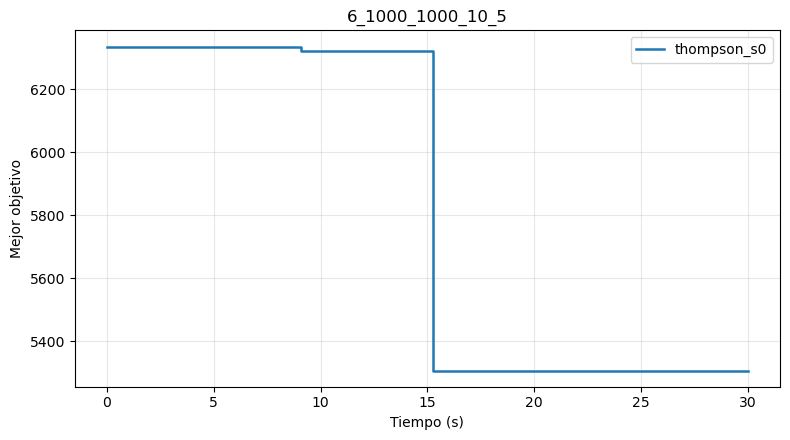

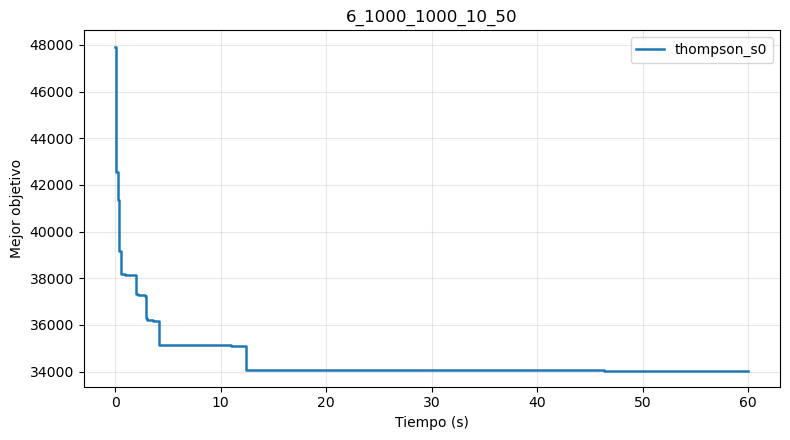

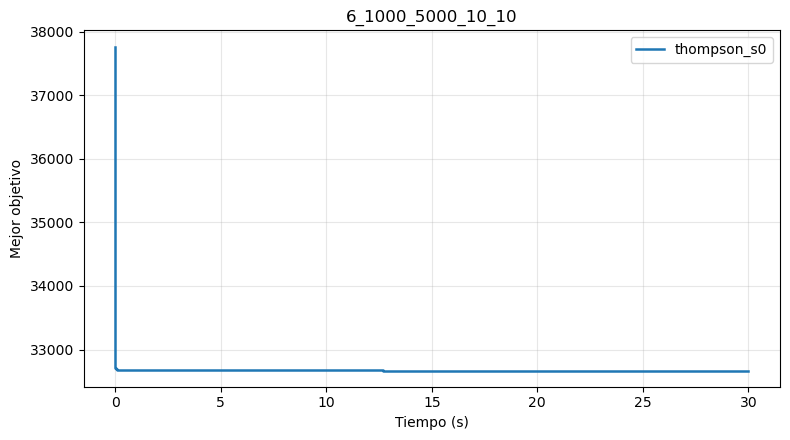

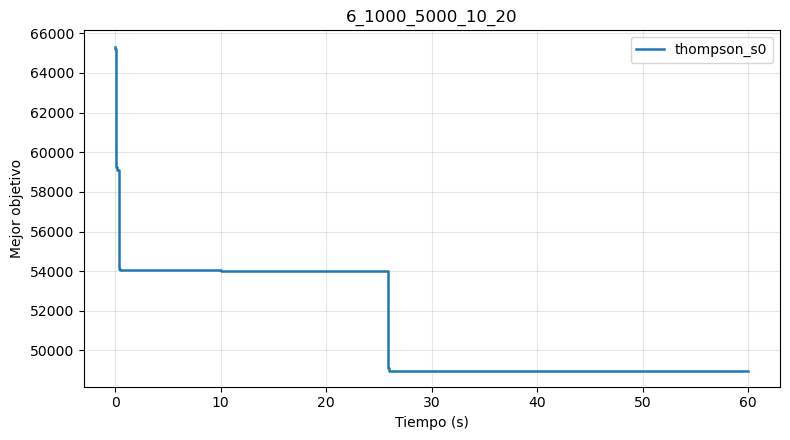

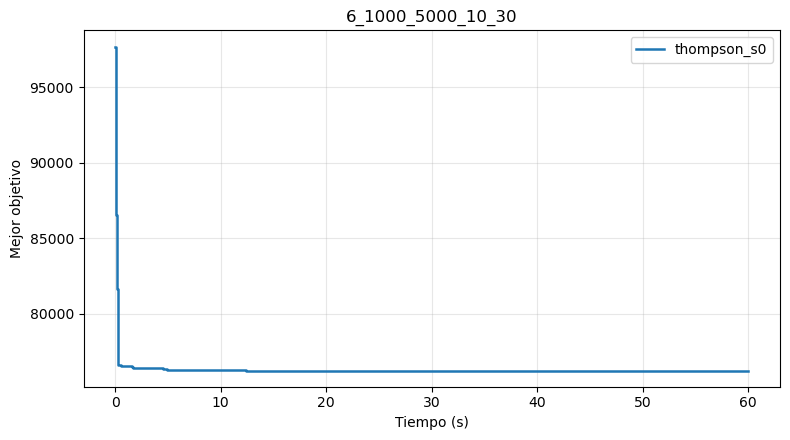

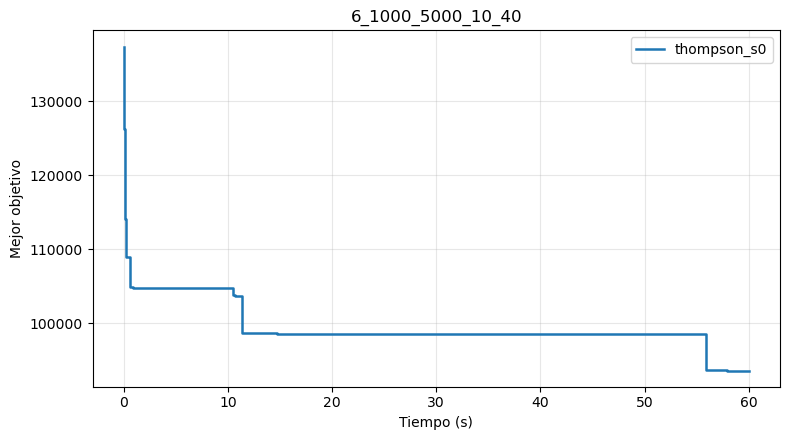

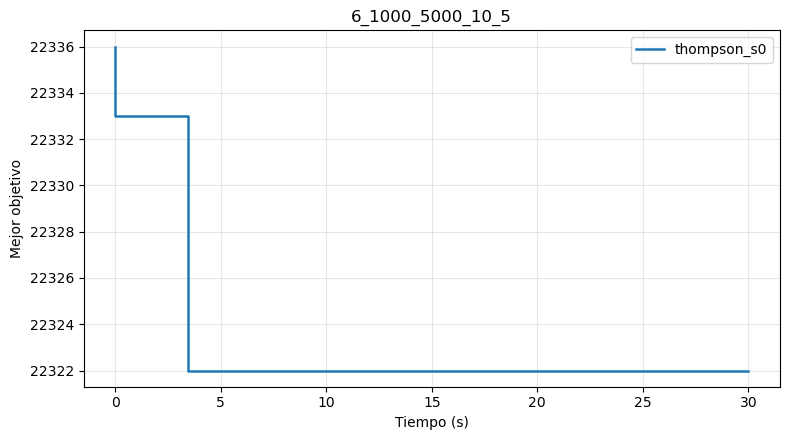

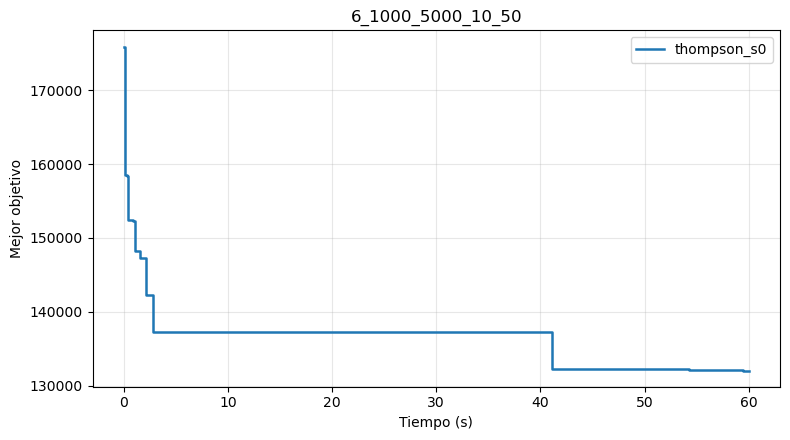

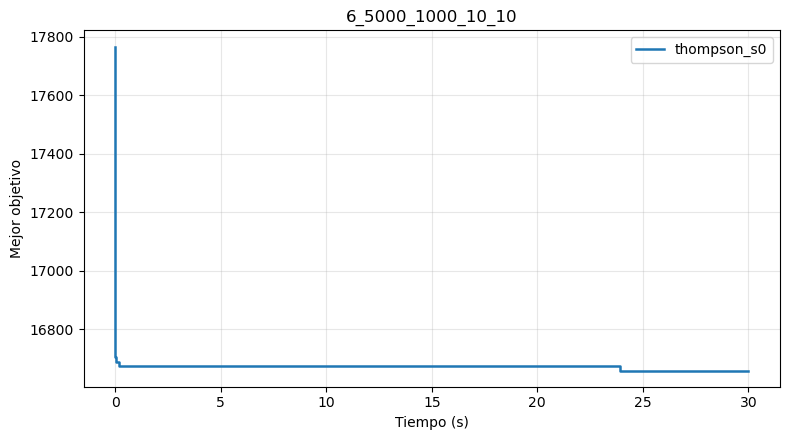

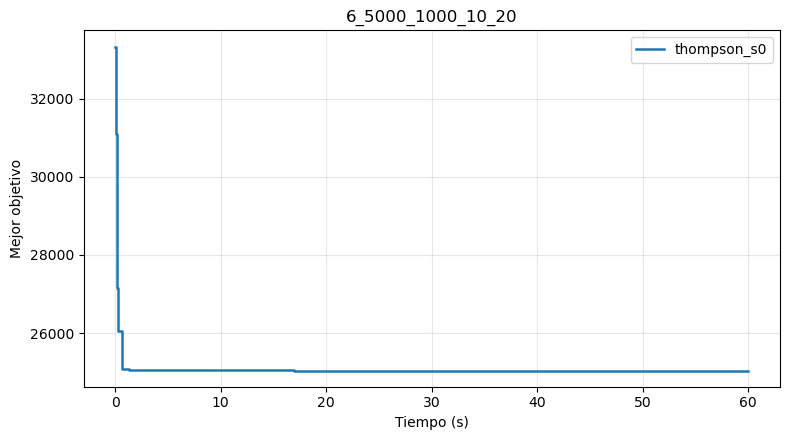

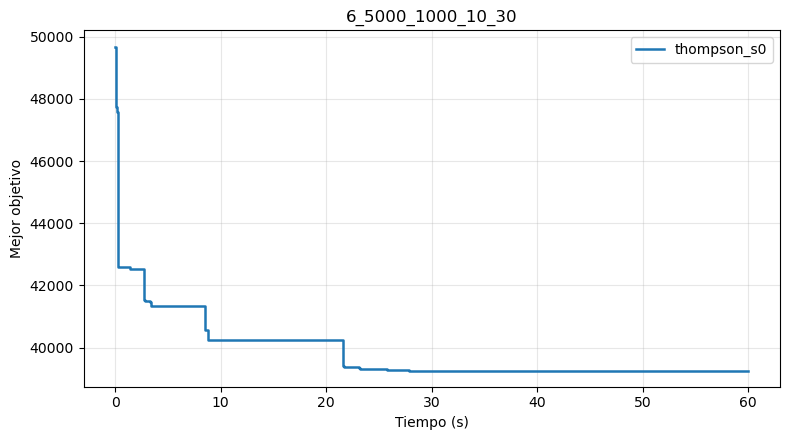

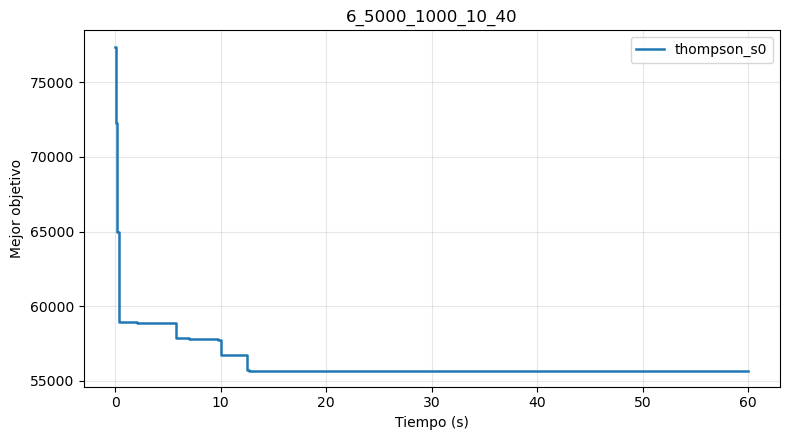

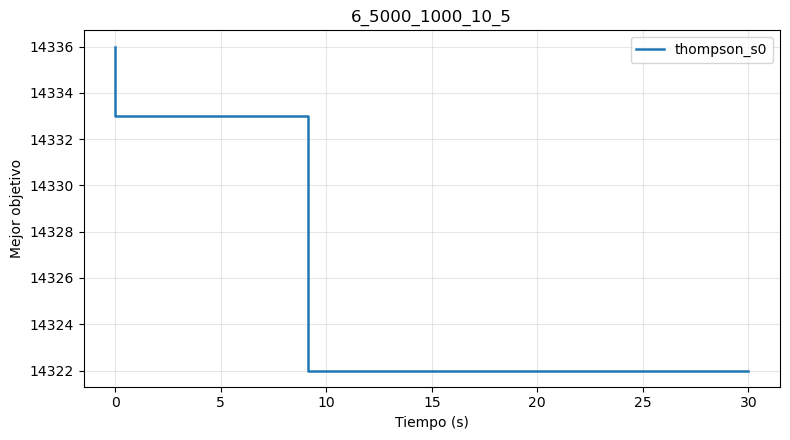

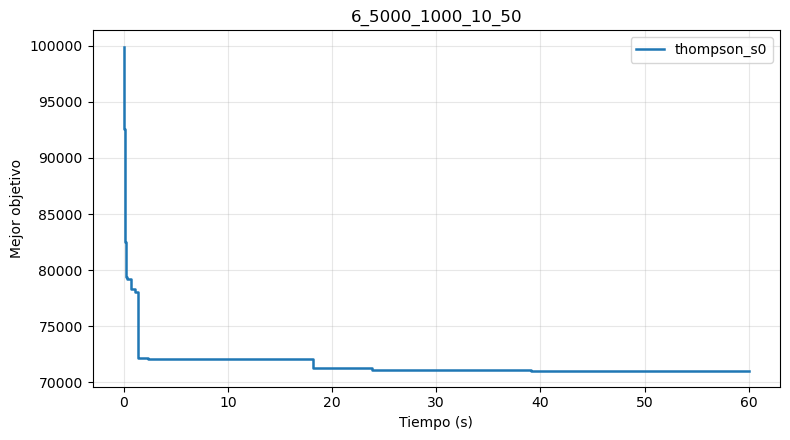

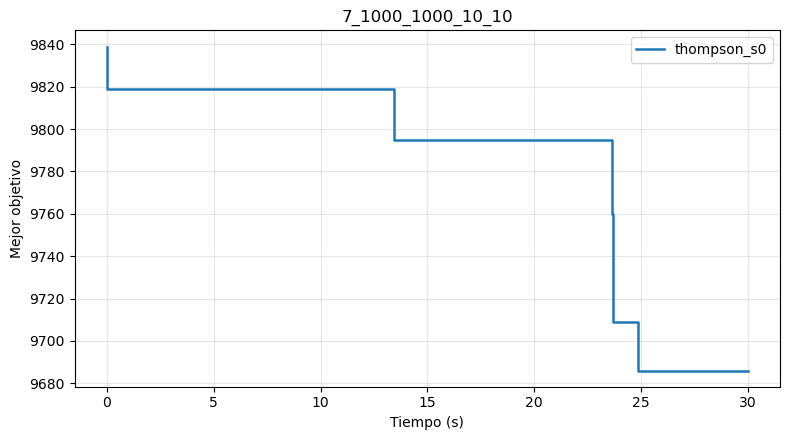

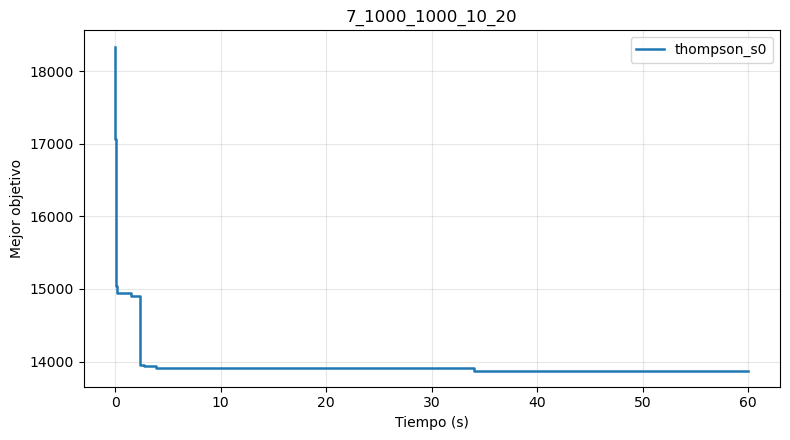

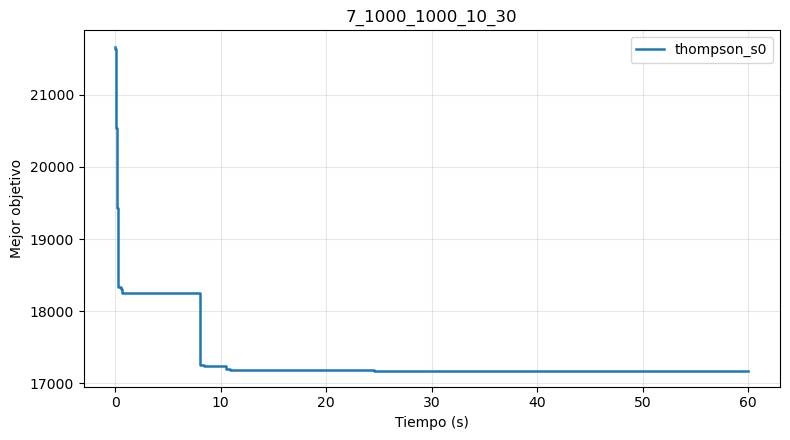

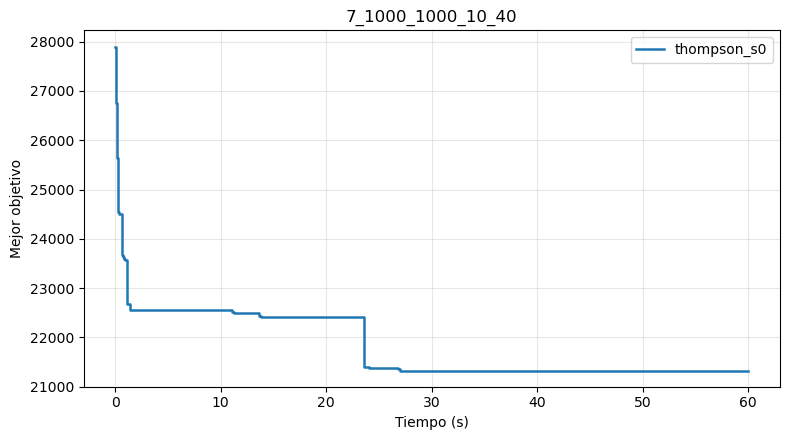

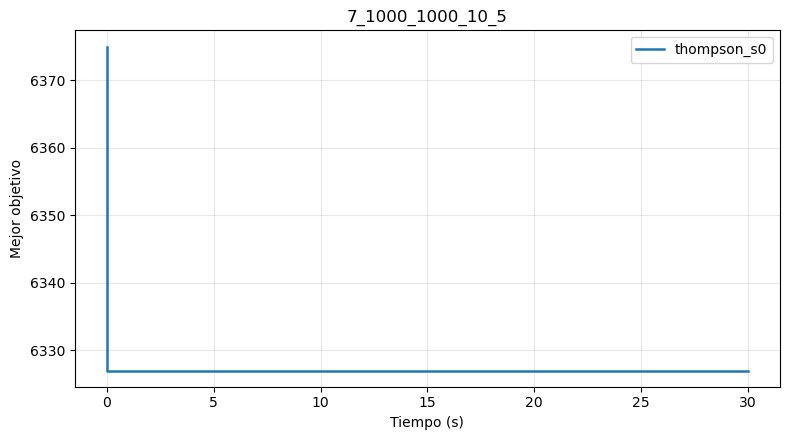

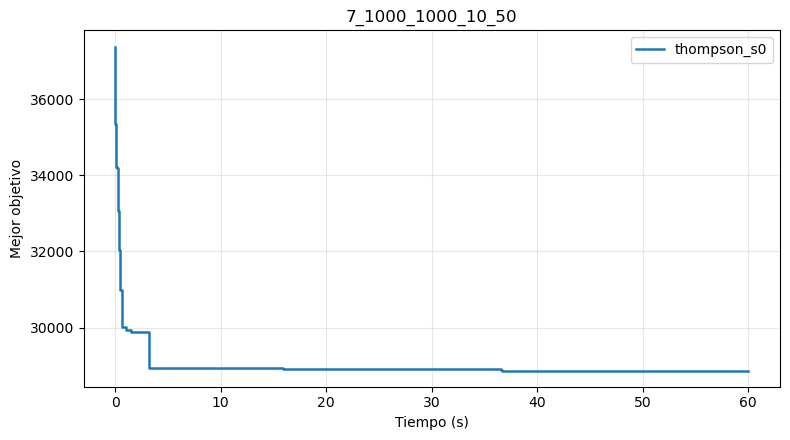

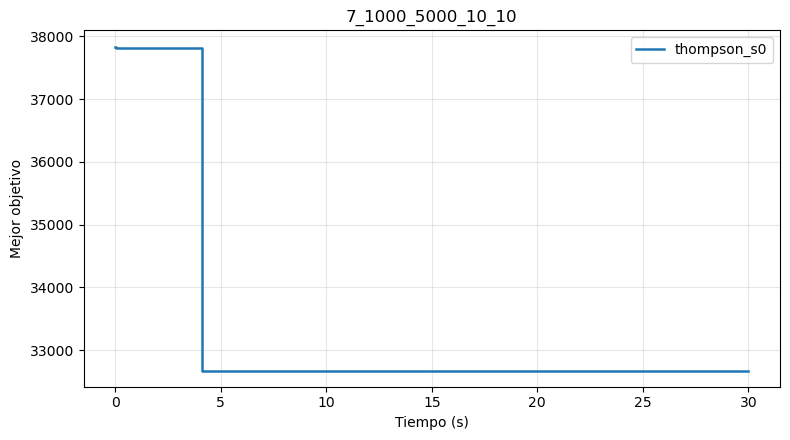

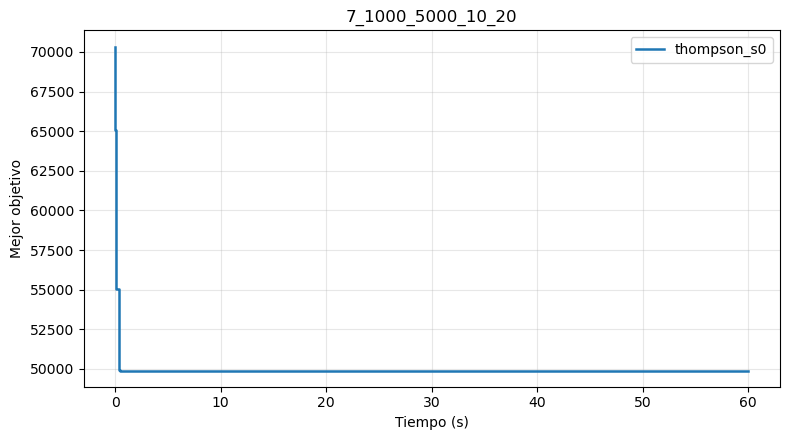

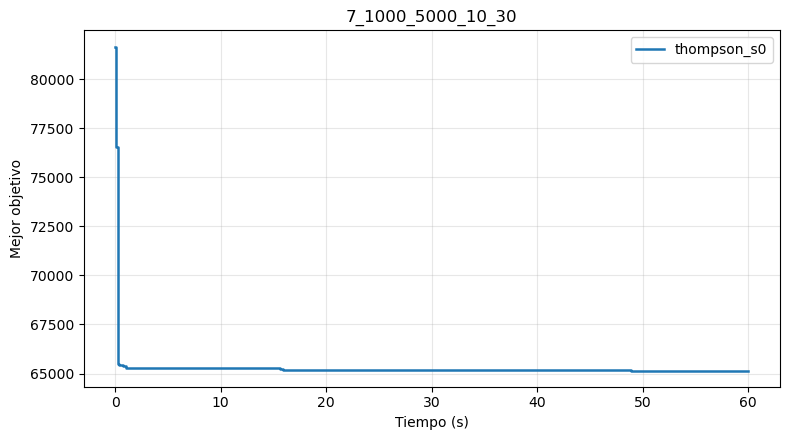

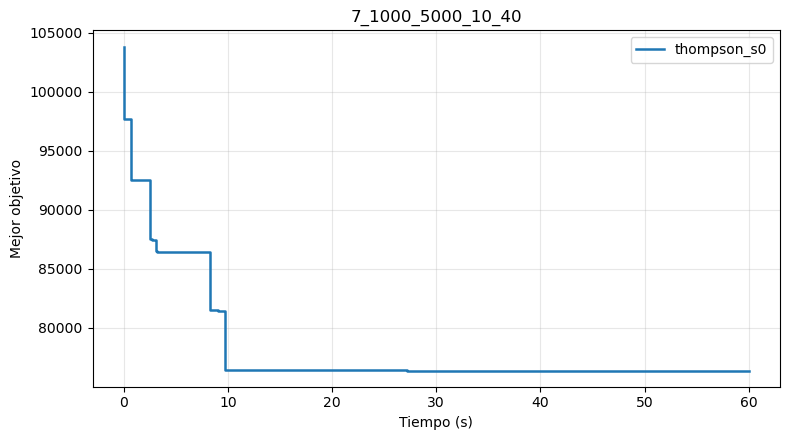

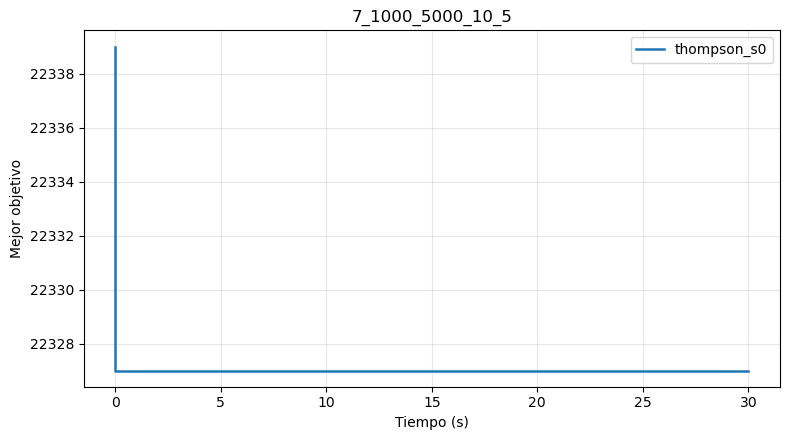

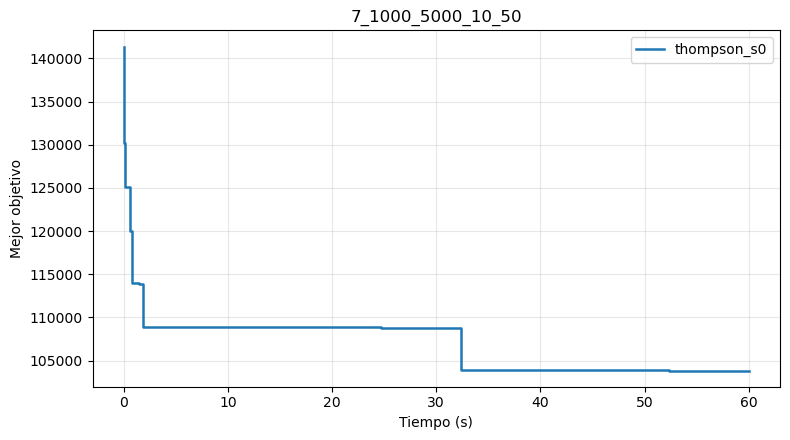

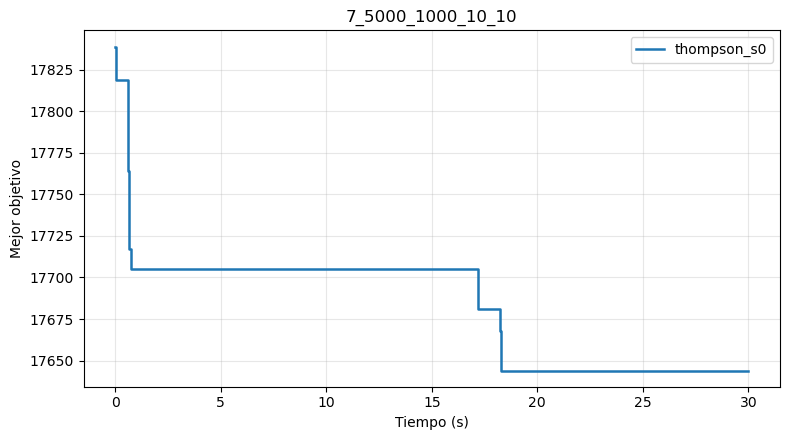

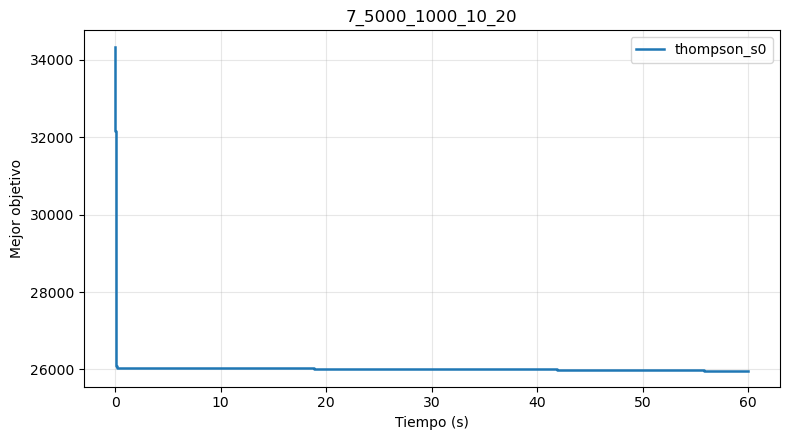

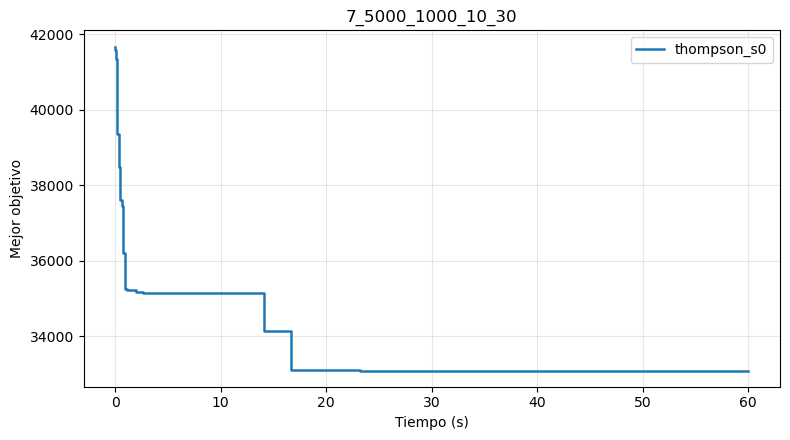

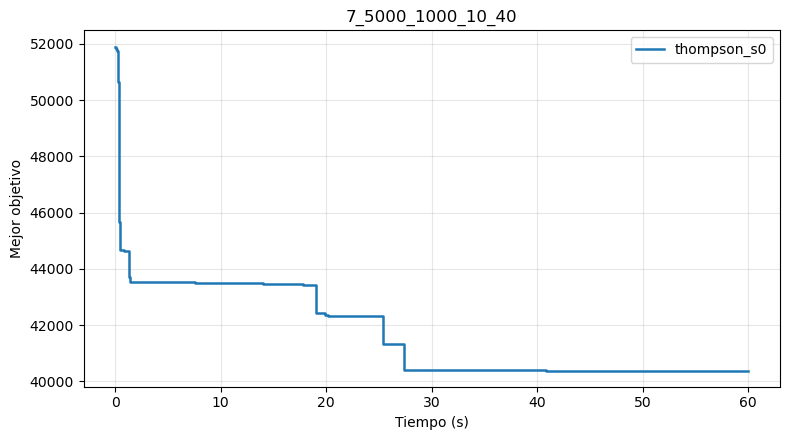

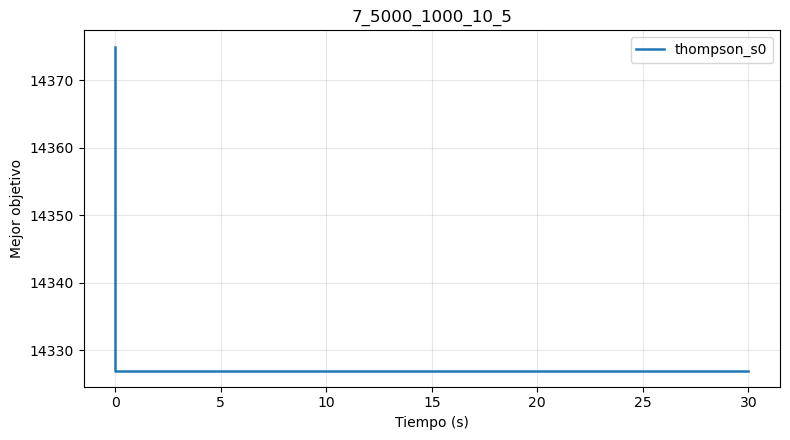

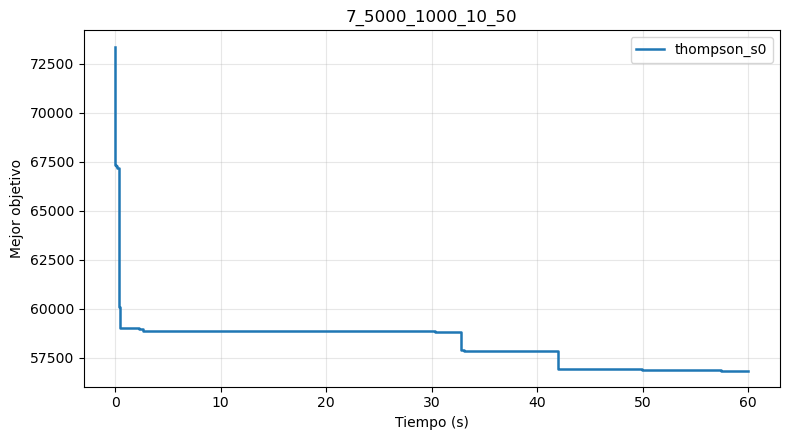

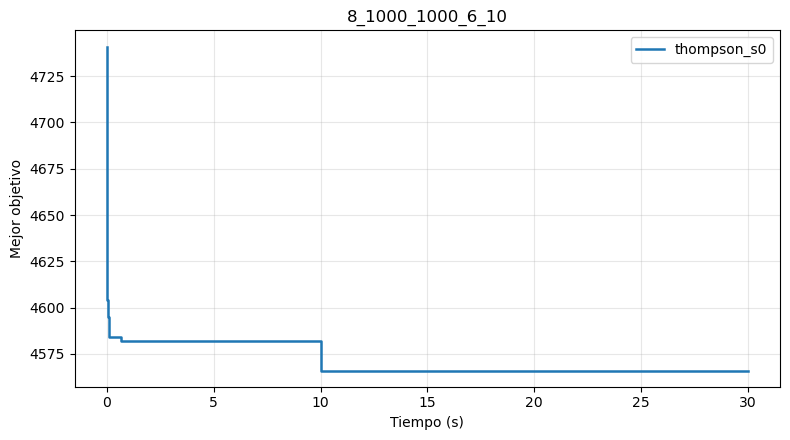

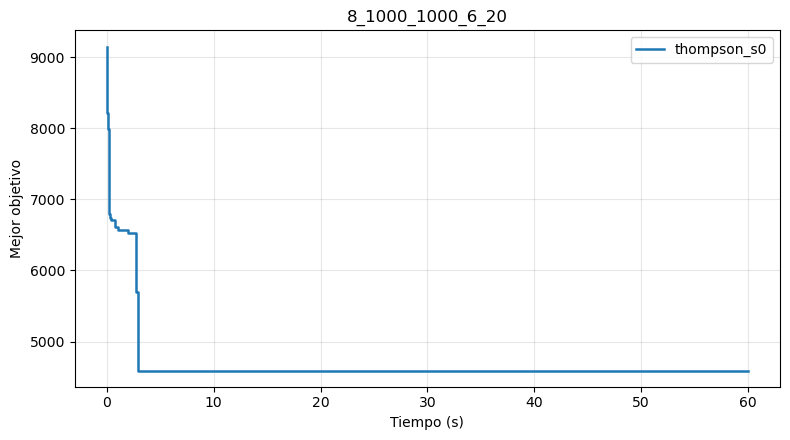

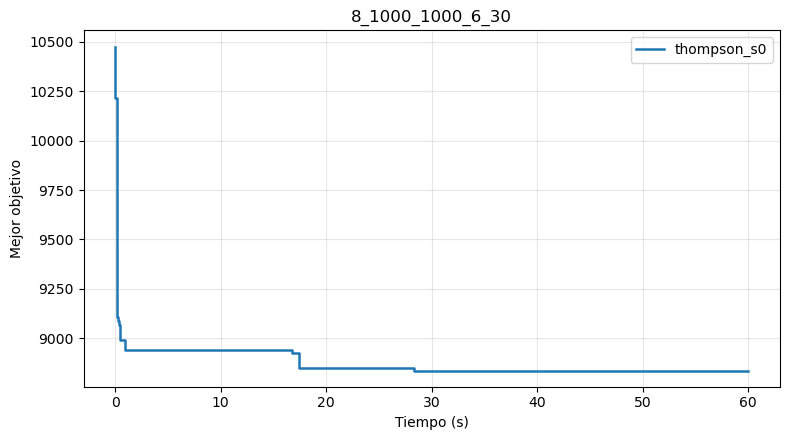

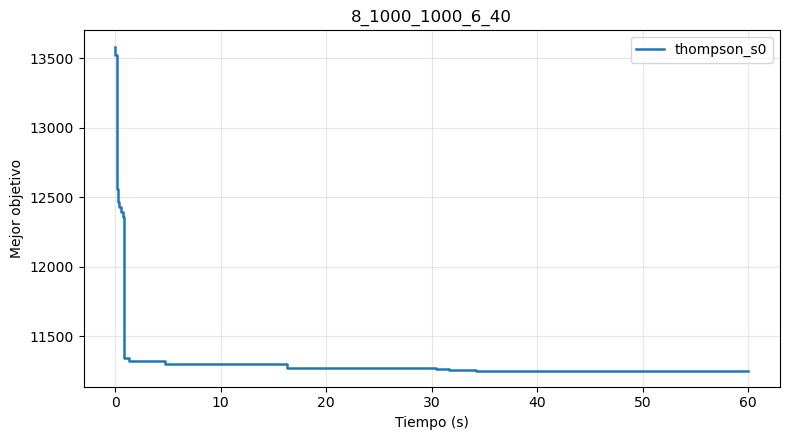

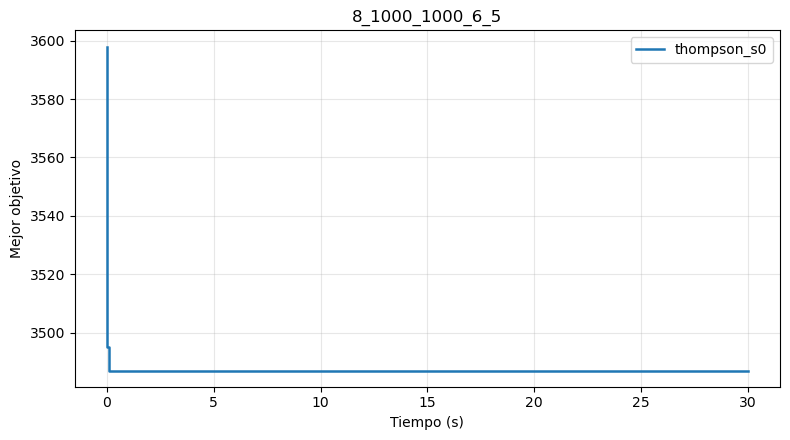

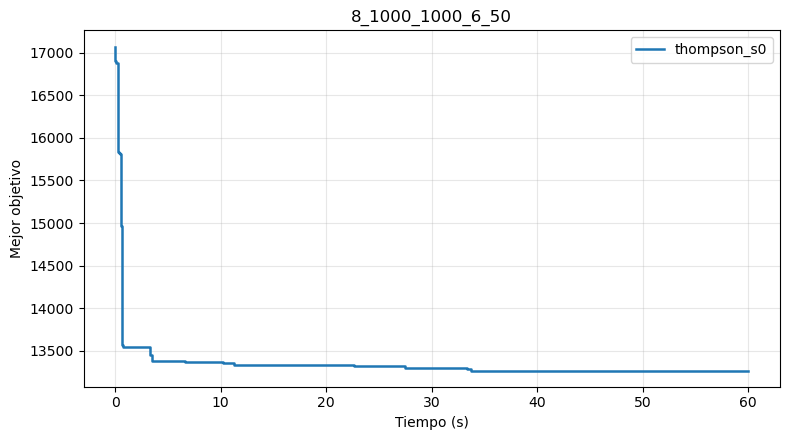

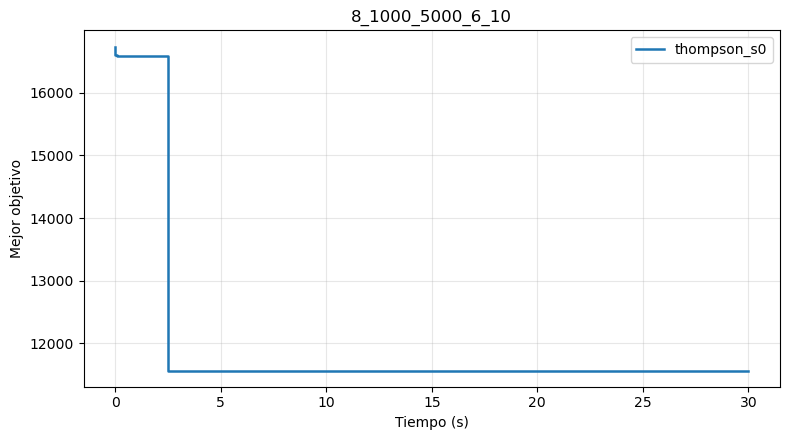

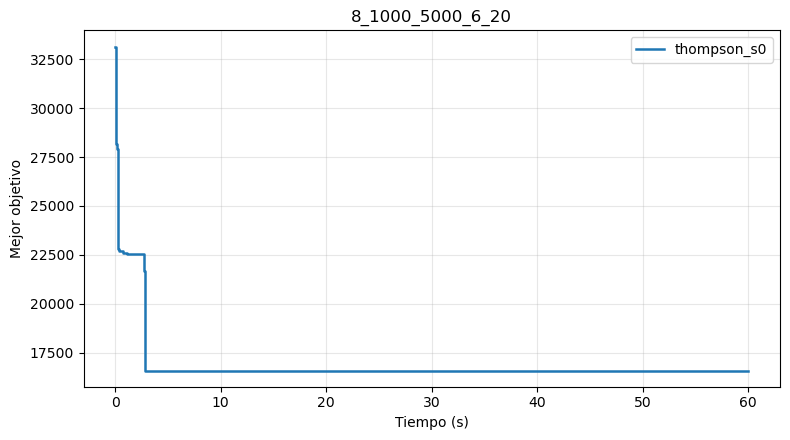

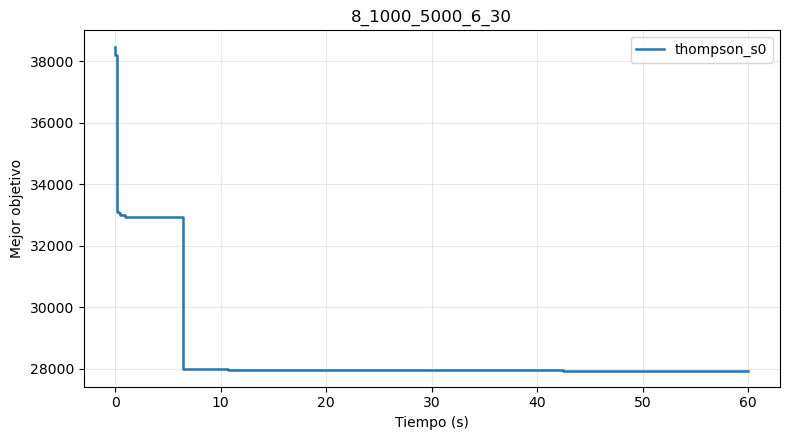

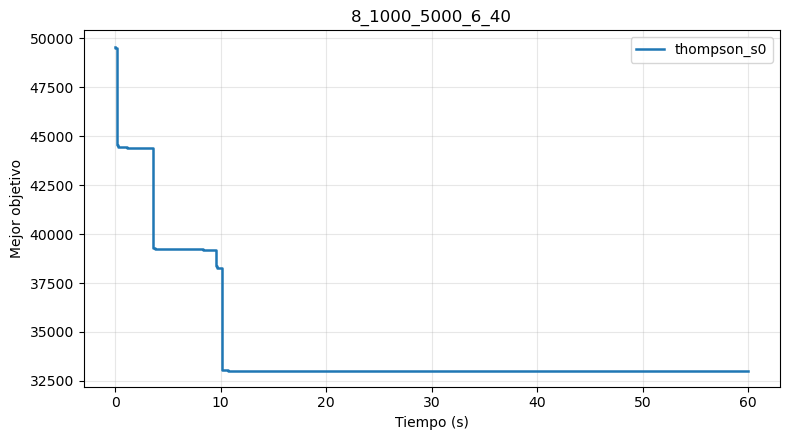

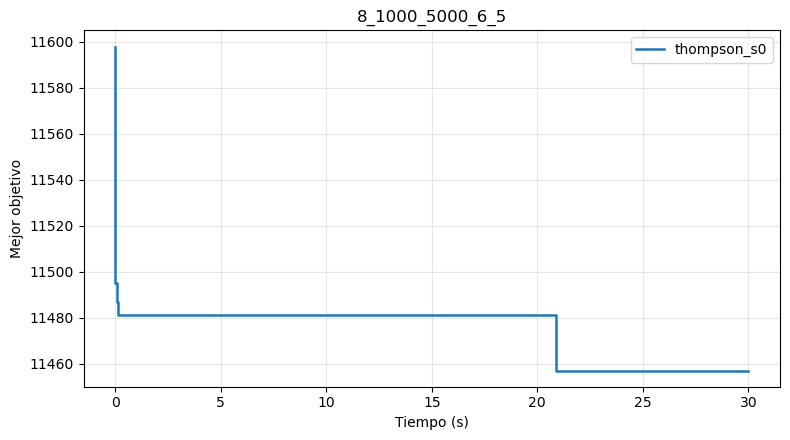

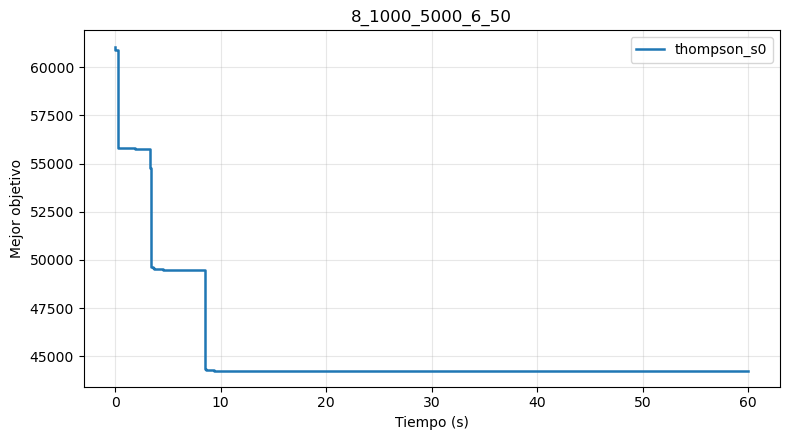

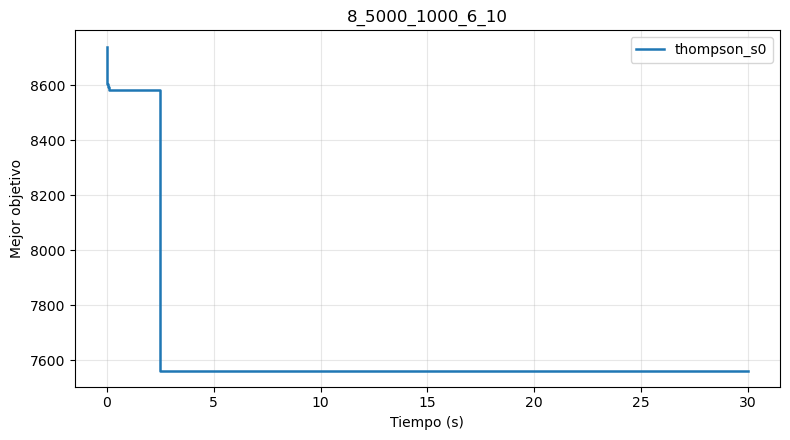

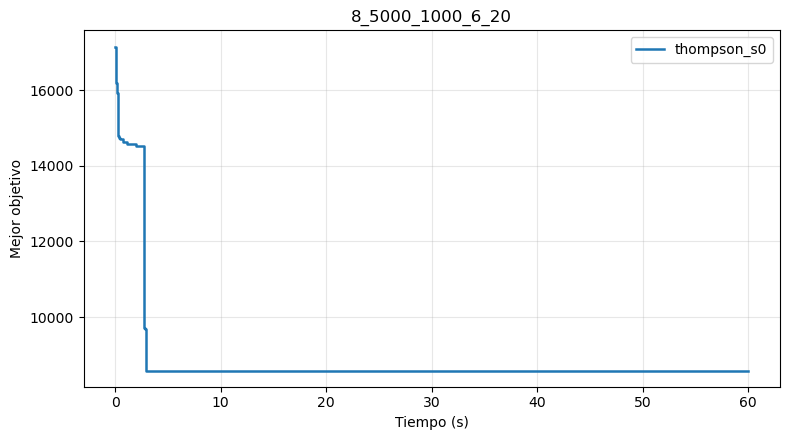

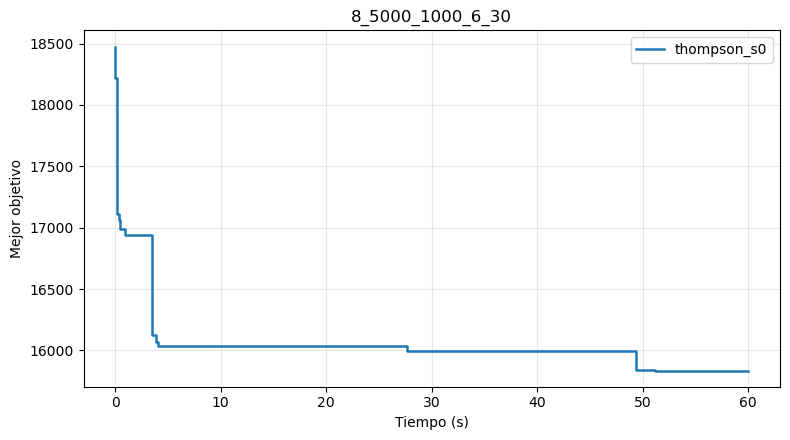

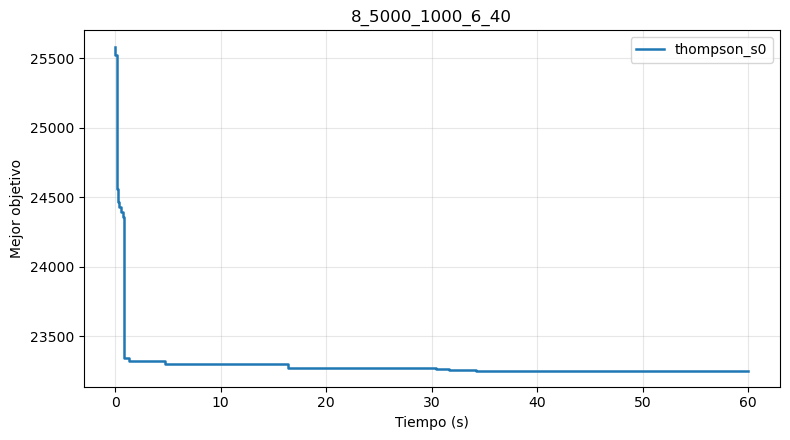

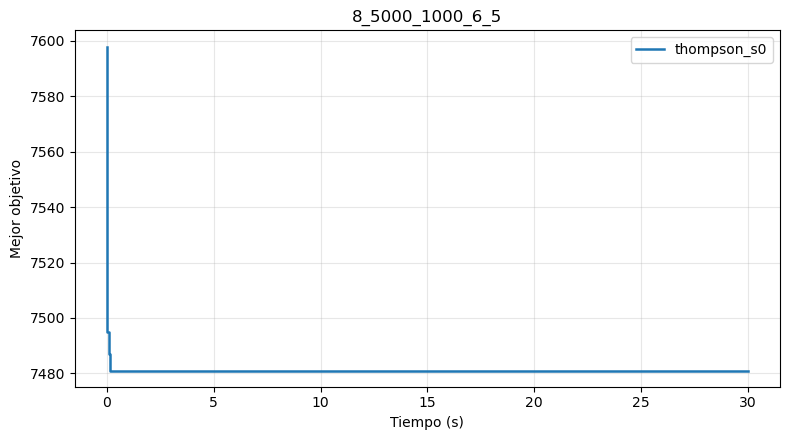

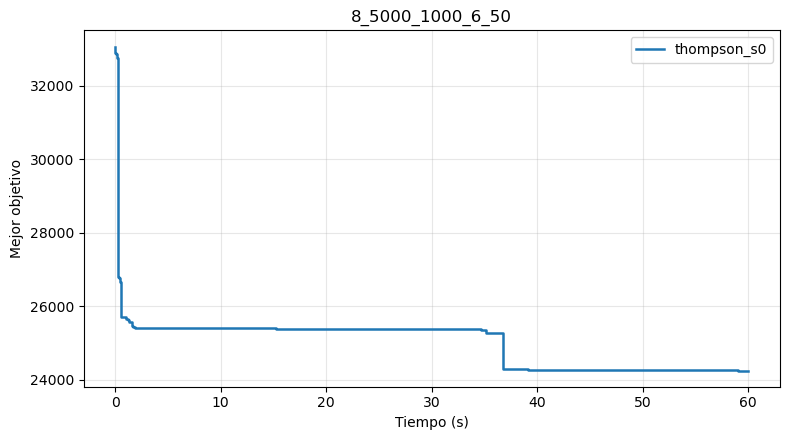

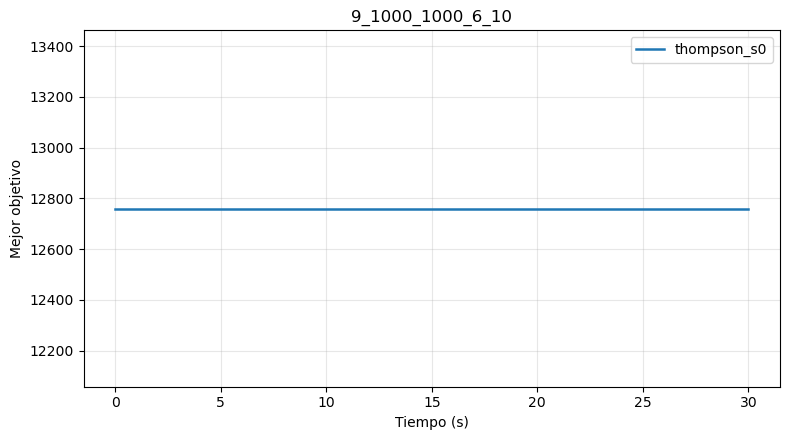

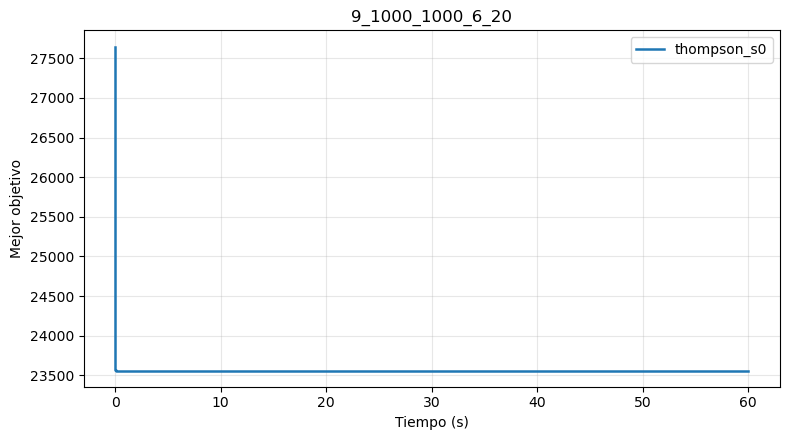

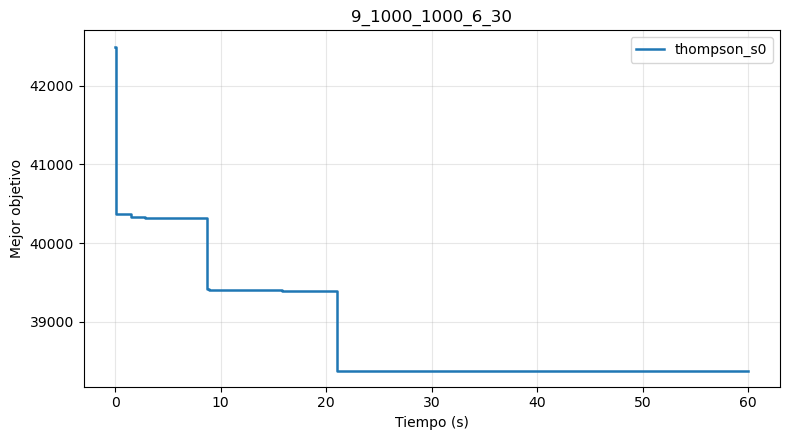

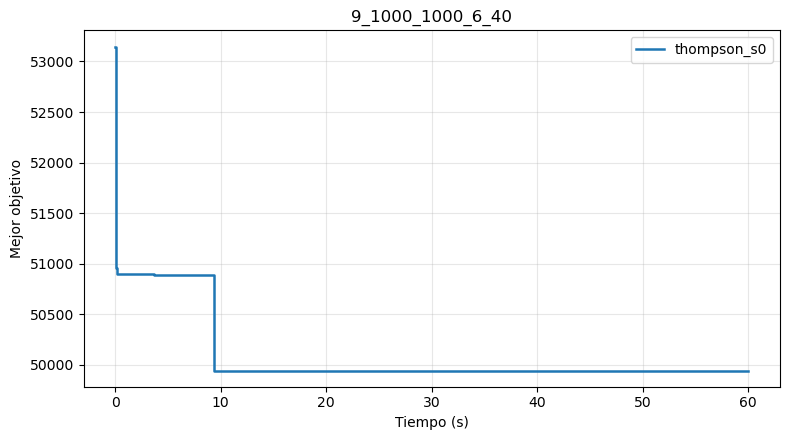

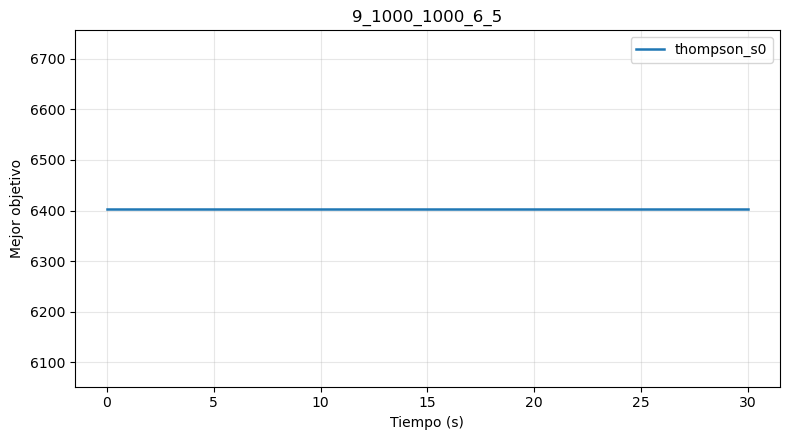

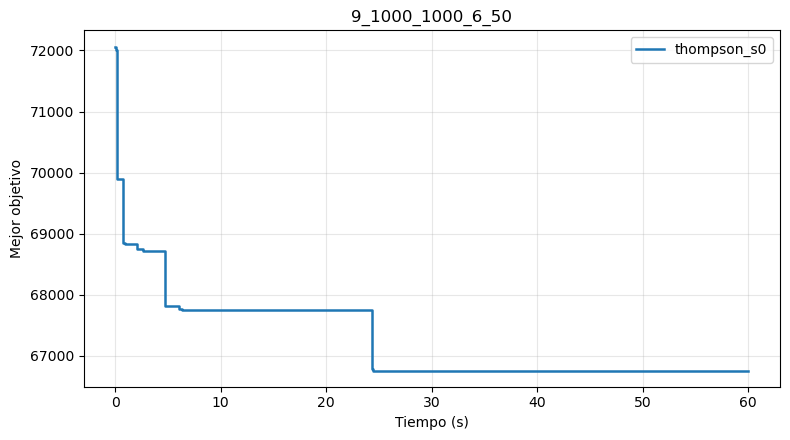

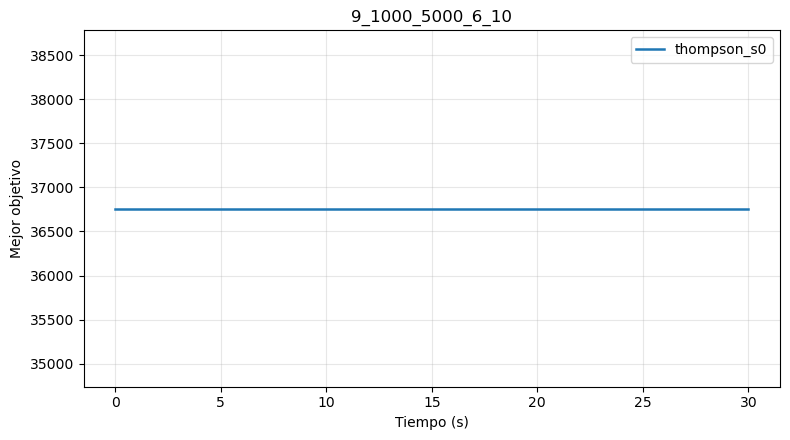

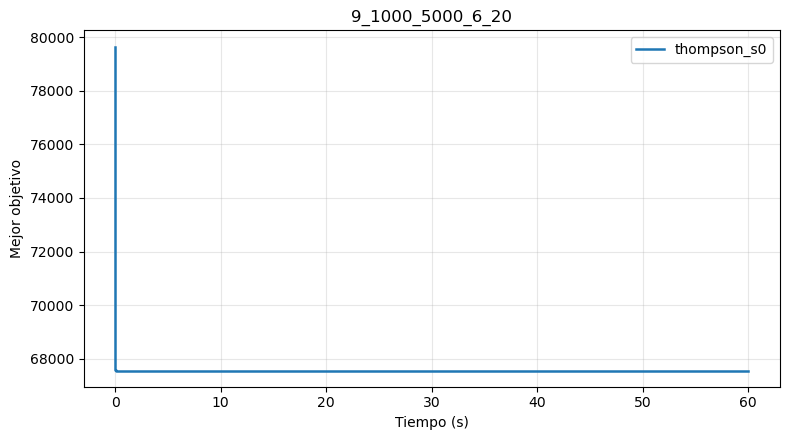

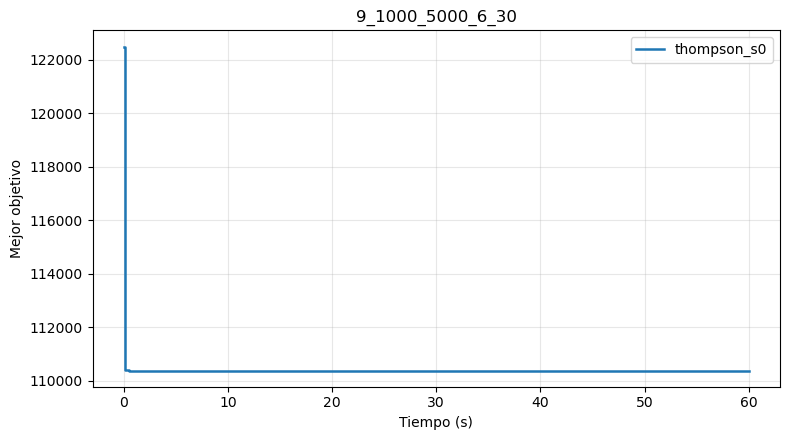

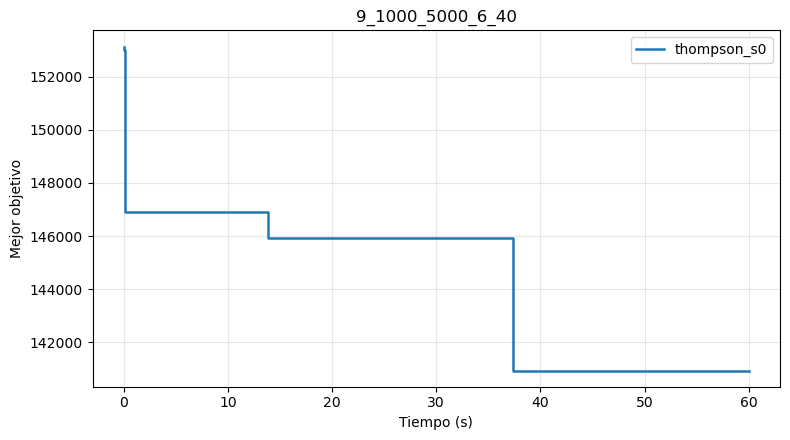

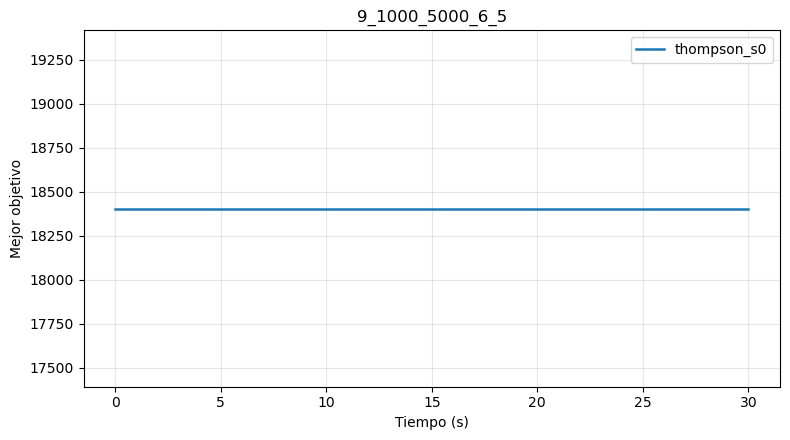

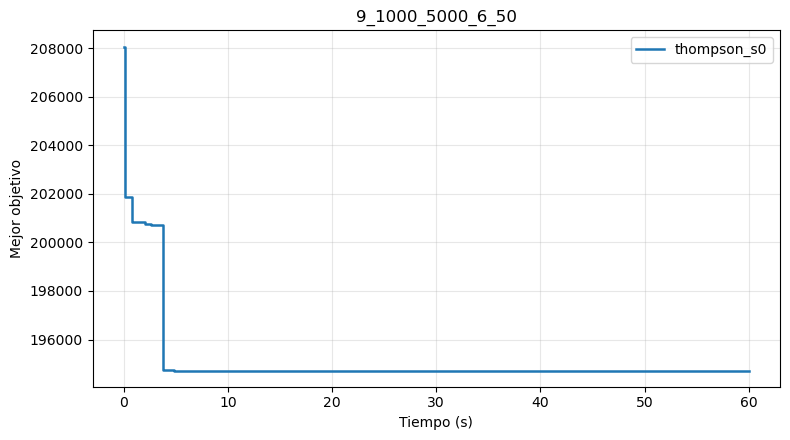

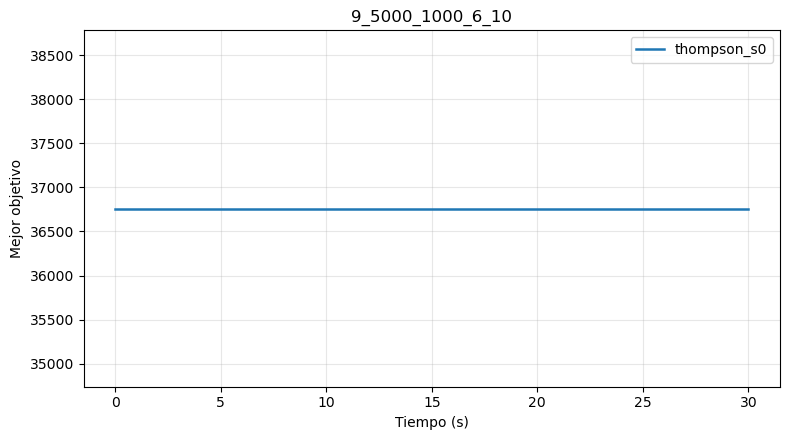

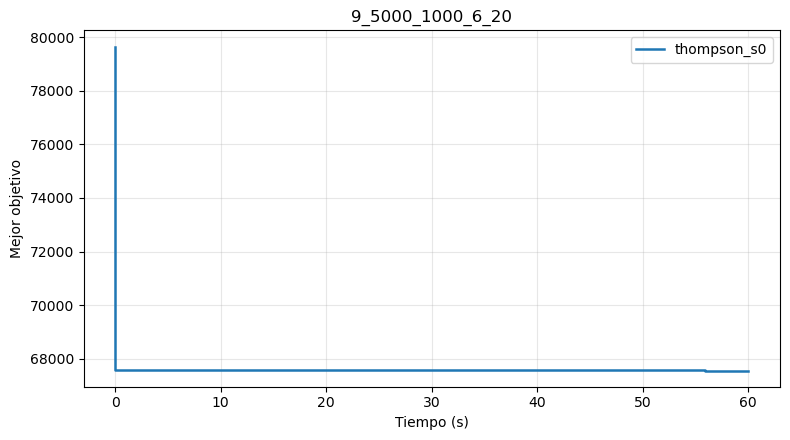

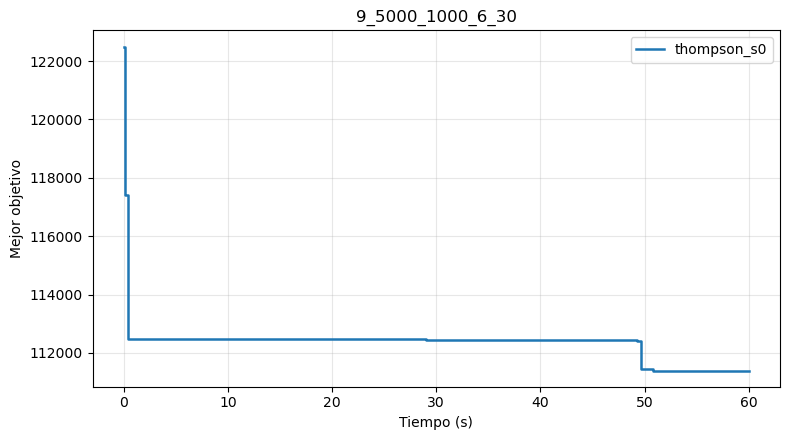

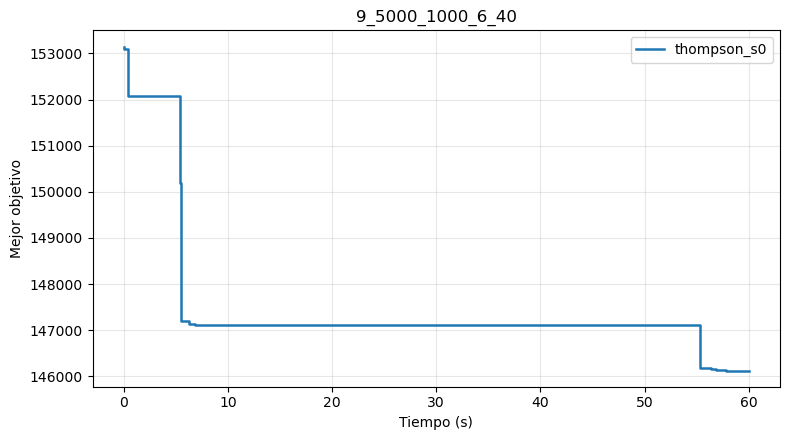

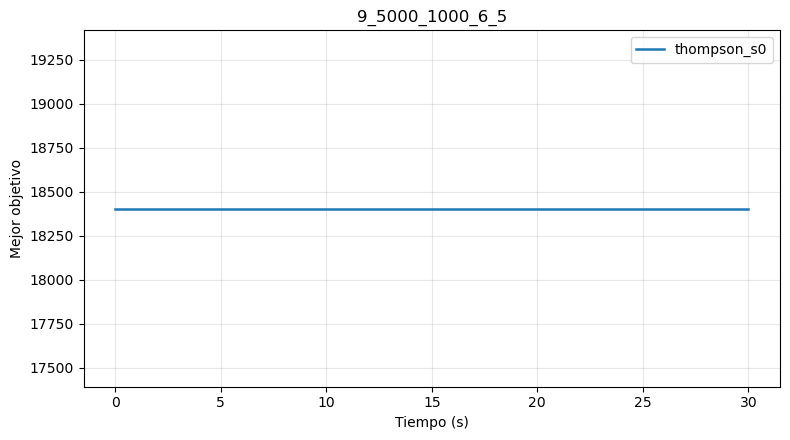

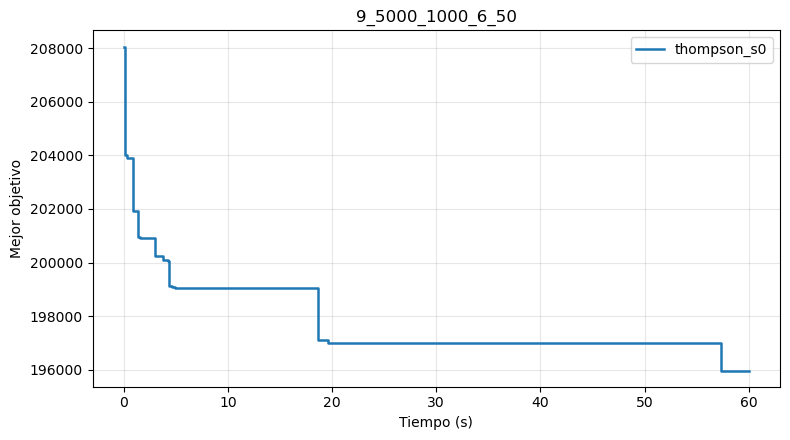

In [4]:
carpetas = ["resultados_thompson_s0"]   # agrega "resultados_exp3_s0" para comparar

instancias = sorted({os.path.basename(f).replace("_evolucion.csv", "")
                     for c in carpetas for f in glob.glob(os.path.join(c, "*_evolucion.csv"))})
for inst in instancias:
    disponibles = [c for c in carpetas if os.path.exists(os.path.join(c, inst + "_evolucion.csv"))]
    graficar(inst, disponibles)

In [5]:
resumen = pd.read_csv(os.path.join("resultados_thompson_s0", "resumen.csv"))
resumen[["instancia", "pares", "obj_inicial", "obj_final", "mejora_%", "mejoras", "t_mejor", "factible"]]

,instancia,pares,obj_inicial,obj_final,mejora_%,mejoras,t_mejor,factible
0,1_1000_1000_6_5.txt,5,7268.0,7268.0,0.00,0,0.000,SI
1,1_1000_1000_6_10.txt,10,14523.0,13462.0,7.31,1,0.005,SI
2,1_1000_1000_6_20.txt,20,32033.0,29901.0,6.66,8,47.330,SI
3,1_1000_1000_6_30.txt,30,53772.0,45450.0,15.48,23,36.664,SI
4,1_1000_1000_6_40.txt,40,69232.0,60030.0,13.29,35,54.290,SI
...,...,...,...,...,...,...,...,...
175,10_5000_1000_10_10.txt,10,19774.0,19774.0,0.00,0,0.000,SI
176,10_5000_1000_10_20.txt,20,34334.0,33210.0,3.27,10,55.594,SI
177,10_5000_1000_10_30.txt,30,53851.0,46697.0,13.28,12,17.218,SI
178,10_5000_1000_10_40.txt,40,76621.0,63994.0,16.48,22,35.003,SI


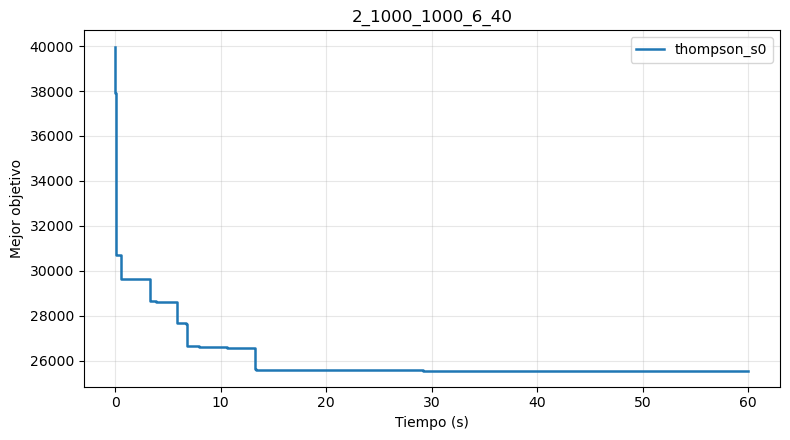

In [11]:
graficar("2_1000_1000_6_40", "resultados_thompson_s0")

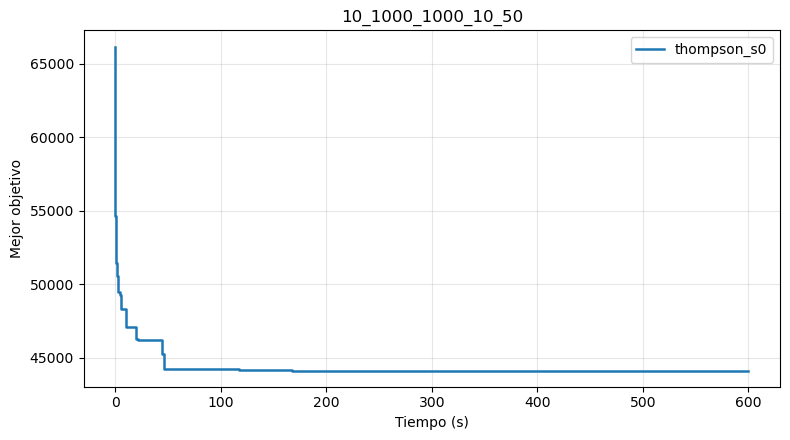

In [12]:
graficar("10_1000_1000_10_50", "resultados_thompson_s0")